## <img style="float: left; padding-right: 10px; width: 45px" src="https://raw.githubusercontent.com/Harvard-IACS/2018-CS109A/master/content/styles/iacs.png"> Course Project

# Decoding the CIA's Corona Spy Satellite Program

**CSCI 89B Natural Langual Processing** <br/>
**Harvard University** / Fall 2025 <br/>
**Author**: Michael Benning

<hr style="height:2.4pt">

[Link to Accompanying You Tube Video](https://youtu.be/eObFeQRcBFU)


## Executive Summary

#### Background

With Cold War tensions rising, presidential hopeful John F. Kennedy's criticism of the Eisenhower administration's foreign policy included raising the specter of a widening ***"missile gap"*** - a potentially ominous Soviet advantage in the number and capability of nuclear missiles.

The perceived threat to national security was real for many Americans.  By the time Kennedy squared off against Richard Nixon in the 1960 election, the Soviet Union had detonated its first two-stage hydrogen bomb (the "RDS-37" in November 1955), launched the world's first artificial satellite ("Sputnik" in November 1957), and declared missiles were rolling off Soviet assembly lines "like sausages" (Soviet Premier Nikita Khrushchev, late-1950s).  And in May 1960, a U-2 spy plane piloted by Francis Gary Powers was shot down over Sverdlovsk, USSR, during a photoreconnaissance mission.  Finding a way to fully assess the threat became a national security priority.
The Central Intelligence Agency's ***CORONA*** spy satellite program launched its first mission with *DISCOVERER I* in 1960.

#### Study Objectives & Deliverables

The objective of the project is (unsupervised) **information extraction**.  Specifically, the project will produce two deliverables:

1.	A **repository** (e.g., a dataframe) detailing *relationship triplets*: a "head", an associated "tail", and the relationship type connecting them.  An example from the subject corpus is:
  - Head: John F. Kennedy School of Government
  - Tail: Harvard University
  - Relationship type: part of
2.	A series of "mind maps" graphically illustrating the extracted relationship triplets (see Figure 1.1 below).

#### Corpus Dataset

The study uses the 372-page document ***CORONA: America's First Satellite Program*** available via the Central Intelligence Agency's Reading Room (links and a more detailed description of the dataset can be found in the *Introduction* section below).

#### Pipeline

The study relies on optical character recognition (OCR) to digitize the text found in the scanned images in the corpus, and two relationship extraction algorithms.  The first is the Relation Extraction By End-to-end Language generation - or REBEL - model available on Hugging Face (see Section 3), and the second is an author-generated, fit-for-purpose, rules-driven algorithm (Section 6).  The former model is fed both sentences and phrases as input and is used to produce mind maps, while the second model is used to produce geographic maps.

#### Conclusions

Most importantly, the study's objective was met:  relationship triplets were extracted and they were used to create mind maps of the information extracted.

Second, at the risk of stating the obvious, an important learning is to always be mindful to align models with what they were designed and trained to do.  It is important to understand the data - in this case a corpus of documents - and choose an appropriate model.  As detailed in Section 6 below, a number of documents in the corpus are not well-suited to the primary model's use case (the REBEL model detailed in Section 3).  And similarly, providing inputs to the model in a way and format consistent with the way it was trained - in this case, sentences instead of phrases - can be expected to produce improved results.

Finally, as an artifact, mind maps come with inherent constraints and limitations.  First, the maps will convey all the information provided - whether there are 5 nodes or 50.  and trying to squeeze that information to a single map and a single page and keep it readable can be a challenge unique to this output type.

#### Future Scope

There are a small number of study improvements that may be prioritized given additional time to progress the study.  Chief among them is simply cleaning up the digitized text.  The optical character recognition piece (Section 2.2) performed well, but the corpus documents contain a substantial volume of redactions, strike-throughs, and hand-written scribbles.  Dealing with these appropriately is a time-consuming job.  In addition, the poor condition of a number of documents in the corpus significantly impacted the performance of the OCR digitization task.

The second study improvement to be prioritized is training both the spaCy named entity recognition model and the REBEL model.  The spaCy model performed well with the exception of classifying persons.  In addition, training the REBEL model is also a priority.  Qualitatively reviewing outputs of the REBEL model suggests there is an opportunity to incorporate corpus-specific triplets to improve overall model accuracy.  In addition, training these two models would be an excellent learning opportunity.

Finally, while considerable time was consumed refining the mind map-generation function to include the desired information and maximize readability, there is room to make the output better.


<a id="contents"></a>

## Notebook contents

- [**1.0 Project Overview**](#Overview)

- [**2.0 Corpus Dataset**](#Dataset)

- [**3.0 The REBEL Model**](#REBEL)

- [**4.0 Applying REBEL**](#APPLICATION)

- [**5.0 REBEL-Based Mind Maps**](#graphs)

- [**6.0 Rules-Driven Model**](#manual)


<a id="Overview"></a>

## 1.0 Project Overview

### 1.1 Introduction

In the late-1950s, Soviet Premier Nikita Khrushchev boasted long-range ballistic missiles were rolling off assembly lines "like sausages". The success in 1955 of *RDS-37* - the Soviets' first hydrogen bomb, and *Sputnik* in 1957 - the world's first artificial satellite lent credence to Khrushchev's claim.

Fear among the American public grew that the United States had fallen far behind in both the number and capability of missiles in the Soviet arsenal.  Presidential candidate John F. Kennedy coined the term ***missile gap*** in 1958 capturing the anxiety felt by Americans that its national security was under threat.

With few human intelligence sources inside the Soviet Union, aerial photography - first from the U-2 spy plane, and later the Corona spy satellite program proved instrumental in assessing Soviet capabilities and shaping America's strategic defense policy.


### 1.2 Corpus Dataset

The Freedom of Information Act of 1966 has made available previously classified Central Intelligence Agency (CIA) documents detailing CORONA's history, technological challenges, triumphs, and central role in intelligence gathering during the Cold War.  Parenthetically, and somewhat confusingly, the CORONA program encompasses a suite of satellites and sub-programs with code names including ARGON, TALENT, LANYARD, and KEYHOLE.

Among the several dozen documents available in the CIA's Reading Room$^1$ concerning the photoreconnaissance program, is ***CORONA: America's First Satellite Program***$^2$.  The 372-page document is actually a collection of documents beginning with a historical overview of the program and includes 10 de-classified memoranda from the Committee on Overhead Reconnaissance (COMOR) detailing the program's design requirements, and priority reconnaissance targets inside the Soviet Union.  In addition, the document includes twelve Photographic Intelligence Reports and two National Intelligence Estimates assessing the national security implications.

$^1$https://www.cia.gov/readingroom/

$^2$https://www.cia.gov/readingroom/document/5076dee1993247d4d82b5c25

### 1.3 Objectives & Deliverables

The objective of the project is (unsupervised) **information extraction**.  Specifically, the project will produce two deliverables:

1.	A **repository** (e.g., a dataframe) detailing relationship triplets contained within the *CORONA: America's First Satellite Program* document.  Relationship triplets include:  a “head”, an associated “tail”, and the type of relationship connecting them.  An example from the subject document is:
  - Head: John F. Kennedy School of Government
  - Tail: Harvard University
  - Relationship type: part of
2.	A series of "mind maps" graphically illustrating that information (see the figure below).  As consuming the relationship triplets in tabular form will be a bit laborious, the mind maps will group the extracted heads and tails and display them with relationships intact.

Given the size of the corpus, it will not be feasible to produce a single mind-map illustrating the whole of the information repository.


### 1.4 Challenges

The corpus document presents a number of natural language processing technical challenges.  First, the document is not digitized text, but rather a scanned image of the original documents saved in PDF form.  In addition, despite de-classification of the individual documents, many memoranda and reports contained in the document remain heavily redacted.  In many cases, the poor overall condition of several documents in the collection has made the scanned copy quite difficult to read and convert to text.

But given the objective of extracting relationship triplets, the most important challenge may be the number of documents within the corpus that contain only limited sentence-based text.  Many such documents - such as *List of Highest Priority Targets, USSR*, and *Comparison of 215 Possible AMM-Associated Facilities at Moscow and Sary-Shagan, USSR* are dominated by lists and tabular data.  Extracting relationship triplets from such documents will be a challenge.


### 1.5 Pipeline

Beginning with the scanned subject corpus document described above (see Figure 1.1 below), the project pipeline consists of an optical character recognition (OCR) step (Section 2.2) to convert images in PDF format to digitized text, and includes the ***Relation Extraction By End-to-end Language generation*** (REBEL) model to identify and extract relationship triplets (Section 3.1).  The spaCy library will be used to parse the text data as sentences and sentence phrases as input to the REBEL model (Section 3.2).  A second rule-driven, REGEX-based relationship extraction algorithm is applied to a single document in the corpus and is detailed in Section 6.  Python's *networkx* library is used to construct the output mind maps (Section 5), and *geopandas* is used to construct geographic maps in Section 6.


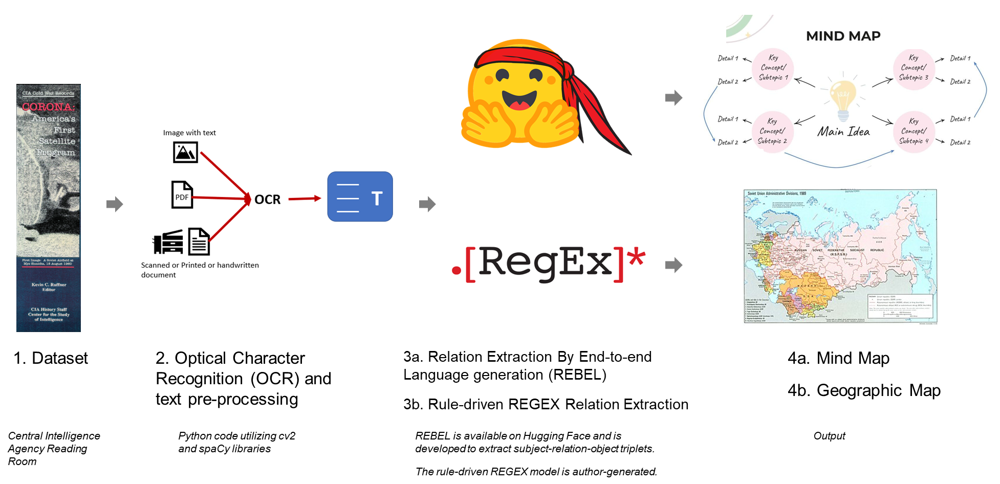

<div align="center">

*Figure 1.1: Pipeline*

</div>


#### 1.5.1 Install Packages

In [ ]:
!pip install pytesseract pdf2image
!apt-get install poppler-utils
!pip install geopandas matplotlib cartopy

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  poppler-utils
0 upgraded, 1 newly installed, 0 to remove and 1 not upgraded.
Need to get 186 kB of archives.
After this operation, 697 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 poppler-utils amd64 22.02.0-2ubuntu0.12 [186 kB]
Fetched 186 kB in 1s (279 kB/s)
Selecting previously unselected package poppler-utils.
(Reading database ... 117528 files and directories currently installed.)
Preparing to unpack .../poppler-utils_22.02.0-2ubuntu0.12_amd64.deb ...
Unpacking poppler-utils (22.02.0-2ubuntu0.12) ...
Setting up poppler-utils (22.02.0-2ubuntu0.12) ...
Processing triggers for man-db (2.10.2-1) ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 96.6 MB/s eta 0:00:00


#### 1.5.2 Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pytesseract
from pdf2image import convert_from_path
import spacy
from transformers import pipeline
import re
import networkx as nx
from textwrap import fill
import itertools
import geopandas

#### 1.5.3 Mount Google Drive

In [ ]:
###  MOUNT GOOGLE DRIVE  ###
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<a id="Dataset"></a>

## 2.0 Corpus Dataset

As described above, the subject dataset ***CORONA: America's First Satellite Program*** is a collection of actual memoranda, intelligence assessments, and reconassaince analysis reports produced by the Central Intelligence Agency (CIA) as part of its mission to assess the Soviet nuclear weapons arsenal and delivery capability.

**Section 2.1** below reads an Excel spreadsheet containing document details, and presents the Table of Contents of the document in a "mind map", or network graph format.

**Section 2.2** performs **Optical Character Recognition** of the scanned PDF document outputting a series of text strings.


### 2.1 Corpus Table of Contents

Given the constraint of producing mind-maps that fit a reasonable image size and maintain readability, the subject document must be sub-divided into logical sections appropriate for its content.

The subject corpus is 372 pages in length and is comprised of three individual parts.  **Parts 2 and 3** are both collections of individual, stand-alone memoranda and reports originally authored by members of the Intelligence Community.  As such, creating individual documents is simply a matter of choosing the appropriate starting and ending page numbers in the subject dataset PDF.

Conversely, **Part 1** of the corpus is a single document comprised of multiple sections (effectively chapters).  Individual section / chapter breaks occur within individual pages making creation of individual documents from Part 1 slightly more involved.

The code cell below reads the Excel spreadsheet (creating a dataframe entitled *df_TOC*) that identifies appropriate breaks in the subject corpus to create manageable documents and avoid figures and images.  For Part 1, *df_TOC* specifies *Begin_text* and *End_text* to specify section / chapter boundaries.

The dataframe's columns and a sample of data are presented below.


In [ ]:
folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
df_TOC = pd.read_excel(
    folder_path + 'History_Contents_2.xlsx',
    converters = {'Begin_text': lambda x: x.replace('\\n', '\n'),
                  'End_text': lambda x: x.replace('\\n', '\n')})

print('COLUMNS:')
for col in df_TOC.columns:
    print(col)


COLUMNS:
Node_1
Node_2
Node_3
Node_4
Begin_page
End_page
Knitted_Text
File_name
Begin_text
End_text


#### 2.1.1 Corpus Table of Contents as a Mind-Map

The code cell below presents the Table of Contents as a mind-map (Figure 2.1).

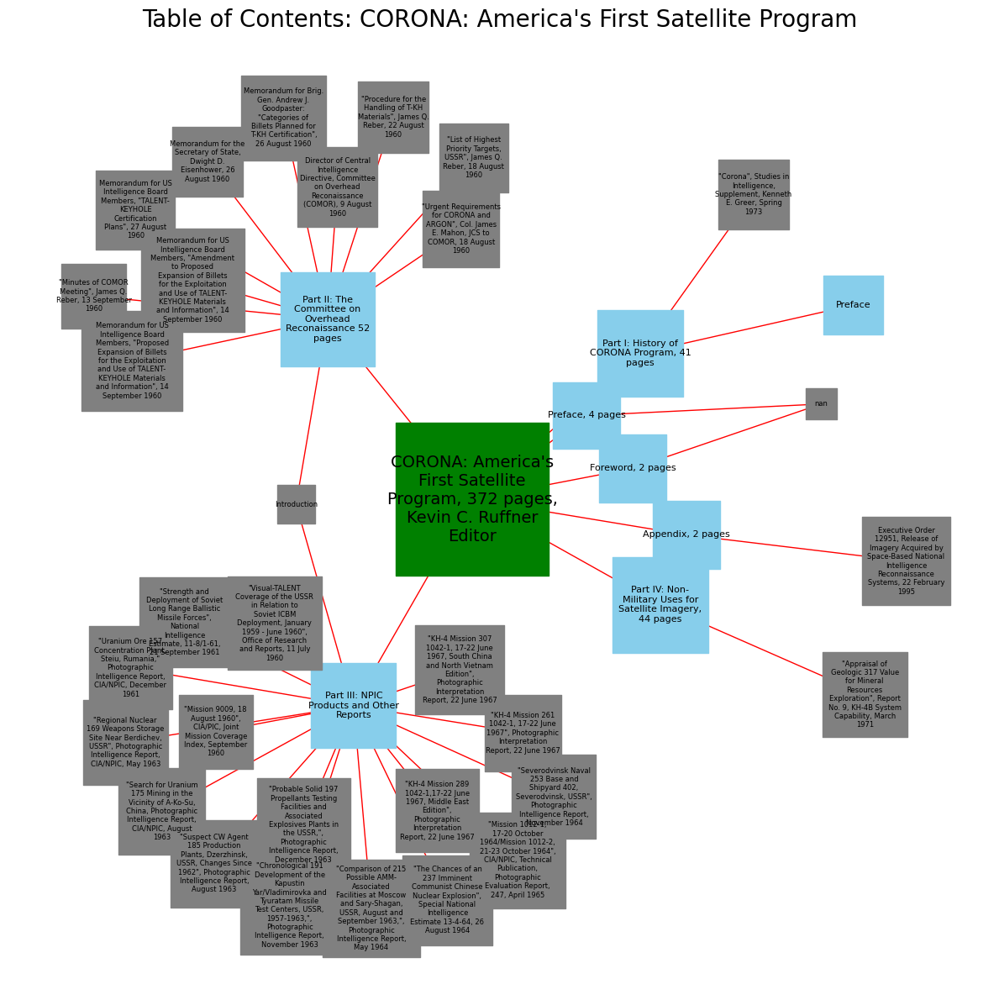

In [ ]:
G_toc = nx.Graph()
column_size = 20

for pair in df_TOC[['Node_1', 'Node_2', 'Node_3', 'Node_4']].values:
    G_toc.add_node(fill(str(pair[0]), column_size))
    G_toc.add_node(fill(str(pair[1]), column_size))
    G_toc.add_node(fill(str(pair[2]), column_size))
    # Node layer 4:
    # G_toc.add_node(fill(str(pair[3]), column_size))
    G_toc.add_edge(fill(str(pair[0]), column_size), fill(str(pair[1]), column_size))
    G_toc.add_edge(fill(str(pair[1]), column_size), fill(str(pair[2]), column_size))
    # Node layer 4:
    # G_toc.add_edge(fill(str(pair[2]), column_size), fill(str(pair[3]), column_size))

node_sizes, node_colors = [], []
big_font_nodes, medium_font_nodes, small_font_nodes = [], [], []
for node in G_toc.nodes():
    label_length = len(node)
    if 'Ruffner' in str(node):
        size = 14000 + (label_length * 40)
        node_sizes.append(size)
        node_colors.append('green')
        big_font_nodes.append(node)
    elif 'Part' in str(node) or 'Appendix' in str(node) or 'Foreword' in str(node) or 'Preface' in str(node):
        size = 2000 + (label_length * 80)
        node_sizes.append(size)
        node_colors.append('skyblue')
        medium_font_nodes.append(node)
    else:
        size = 600 + (label_length * 40)
        node_sizes.append(size)
        node_colors.append('gray')
        small_font_nodes.append(node)

pos = nx.kamada_kawai_layout(G_toc)
# pos = nx.spring_layout(G_toc, k = 0.5)
big_font_pos = {n: pos[n] for n in big_font_nodes if n in pos}
medium_font_pos = {n: pos[n] for n in medium_font_nodes if n in pos}
small_font_pos = {n: pos[n] for n in small_font_nodes if n in pos}

plt.figure(figsize = (12, 12))

nx.draw_networkx_labels(G_toc.subgraph(small_font_nodes), small_font_pos, font_size = 6)
nx.draw_networkx_labels(G_toc.subgraph(medium_font_nodes), medium_font_pos, font_size = 8)
nx.draw_networkx_labels(G_toc.subgraph(big_font_nodes), big_font_pos, font_size = 14)

nx.draw(G_toc,
        pos = pos,
        with_labels = False,
        # with_labels = True,
        node_color = node_colors,
        node_shape = 's',
        # node_shape = 'o',
        node_size = node_sizes,
        edge_color = 'red',
        width = 1
        )

plt.title("Table of Contents: CORONA: America's First Satellite Program", fontsize = 20)
plt.tight_layout()
plt.show();

<div align="center">

*Figure 2.1: Dataset Table of Contents*

</div>

### 2.2 Optical Character Recognition

The functions below convert the scanned images (saved in PDF format) of the original documents to text.  The function *preprocess_image* converts the image to grayscale and applies thresholding to improve optical character recognition (OCR) accuracy.


In [ ]:
def preprocess_image(image):
    # Convert the PIL image to a NumPy array:
    img_array = np.array(image)

    # Convert to grayscale:
    gray_image = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)

    # Apply binary thresholding to ensure the image is black and white:
    # The THRESH_OTSU method finds the optimal threshold value
    thresholded_image = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]

    return thresholded_image

def ocr_pdf_with_preprocessing(pdf_path, first_page, last_page, output_filename, folder_path):
    try:
        print(f'Converting {pdf_path} to images...')
        pages = convert_from_path(pdf_path, first_page = first_page, last_page = last_page, dpi = 300)
    except Exception as e:
        print(f'Error converting PDF: {e}')
        return

    full_text = ''
    for i, page in enumerate(pages):
        preprocessed_img = preprocess_image(page)
        text = pytesseract.image_to_string(preprocessed_img)
        full_text += f'--- Page {i+1} ---\n{text}\n\n'

    with open(folder_path + output_filename, 'w', encoding = 'utf-8') as f:
        f.write(full_text)

    print(f'OCR complete. Text saved to {folder_path}.')
    return full_text

#### 2.2.1 Image-to-Text Conversion: Part 1

The cell below converts a list of beginning and end pages in the dataset PDF and writes them to individual text files.  The cell is specific to **Part 1** of the subject document.

As described above, Part 1 consists of multiple chapters and contains a number of figures and images.  This method of performing OCR in "chunks" is required to avoid non-text items and create stand-alone chapters.


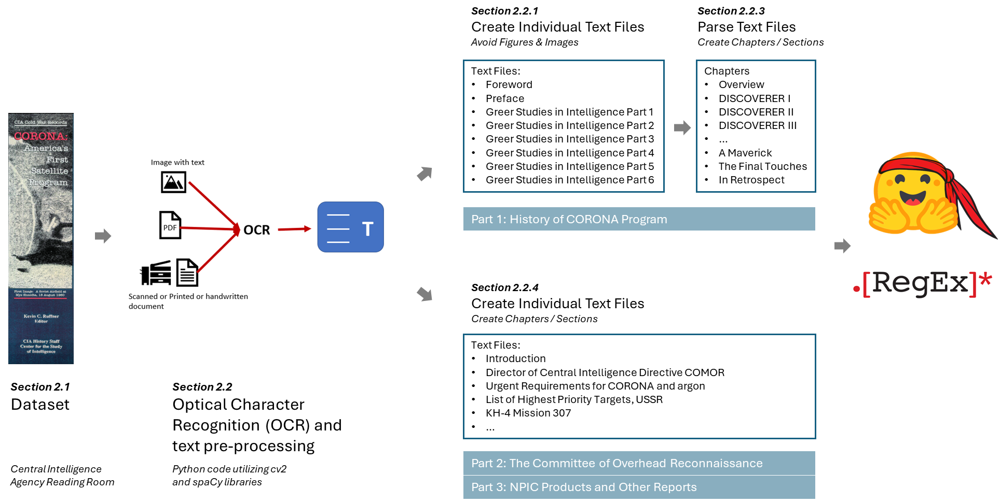

<div align="center">

*Figure 2.2: Pre-Processing Pipeline*

</div>


In [ ]:
# Tuple format: (pdf file path, page start, page end, filename, path to Google drive folder)
pdf_file = r'/content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf'
folder_path = r'/content/drive/MyDrive/89B Project Data Files/'

extractions_list = [
    (pdf_file, 10, 15, 'Corona_history_Foreword', folder_path),
    (pdf_file, 17, 18, 'Corona_history_Part_1_History_of_Corona', folder_path),
    (pdf_file, 19, 28, 'Greer_Studies_in_Intelligence_part_1', folder_path),
    (pdf_file, 30, 30, 'Greer_Studies_in_Intelligence_part_2', folder_path),
    (pdf_file, 32, 38, 'Greer_Studies_in_Intelligence_part_3', folder_path),
    (pdf_file, 40, 40, 'Greer_Studies_in_Intelligence_part_4', folder_path),
    (pdf_file, 42, 50, 'Greer_Studies_in_Intelligence_part_5', folder_path),
    (pdf_file, 52, 55, 'Greer_Studies_in_Intelligence_part_6', folder_path),
    ]

for segment in extractions_list:
    print('\nFile Name:', segment[3], ' Pages:', segment[1], '-', segment[2])
    extracted_text = ocr_pdf_with_preprocessing(segment[0], segment[1], segment[2], segment[3], segment[4])



File Name: Corona_history_Foreword  Pages: 10 - 15
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

File Name: Corona_history_Part_1_History_of_Corona  Pages: 17 - 18
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

File Name: Greer_Studies_in_Intelligence_part_1  Pages: 19 - 28
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

File Name: Greer_Studies_in_Intelligence_part_2  Pages: 30 - 30
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

F

#### 2.2.2 Knit the Part 1 Text Files

The following cell "knits" the text files generated in Section 2.2.1 into a single text string and prints the first 1000+ characters.  Again, only Part 1 of the subject dataset document is impacted.


In [ ]:
pdf_file = r'/content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf'
folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
Part_1 = ''

extractions_list = [
    (pdf_file, 10, 15, 'Corona_history_Foreword', folder_path),
    (pdf_file, 17, 18, 'Corona_history_Part_1_History_of_Corona', folder_path),
    (pdf_file, 19, 28, 'Greer_Studies_in_Intelligence_part_1', folder_path),
    (pdf_file, 30, 30, 'Greer_Studies_in_Intelligence_part_2', folder_path),
    (pdf_file, 32, 38, 'Greer_Studies_in_Intelligence_part_3', folder_path),
    (pdf_file, 40, 40, 'Greer_Studies_in_Intelligence_part_4', folder_path),
    (pdf_file, 42, 50, 'Greer_Studies_in_Intelligence_part_5', folder_path),
    (pdf_file, 52, 55, 'Greer_Studies_in_Intelligence_part_6', folder_path),
    ]

for file in extractions_list:
    with open(folder_path + file[3], 'r', encoding = 'utf-8') as f:
        f = f.read()
        Part_1 = Part_1 + f
print('Concatenated Text:\n', Part_1[0:1156])

Concatenated Text:
 --- Page 1 ---
Foreword

CORONA: America’s First Satellite Program

Since the CORONA satellite made its first successful flight in August 1960,
the Intelligence Community’s overhead reconnaissance programs have been
among the nation’s most closely guarded secrets. The end of the Cold War,
however, has at last made it possible to declassify both information and
imagery from the first American satellite systems of the 1960s. To do this,
President William Clinton in February of this year ordered the declassifica-
tion within 18 months of historical intelligence imagery from the early sat-
ellite systems known as the CORONA, ARGON, and LANYARD. Because
the President’s Executive Order 12951 (see appendix) envisions scientific
and environmental uses for this satellite imagery, the declassified photo-
graphs will be transferred to the National Archives with a copy sent to the

US Geological Survey. Vice President Albert Gore, who first urged the

Intelligence Community to 

#### 2.2.3 Parse Part 1 Text

The following code parses the concatenated text above into individual sections / chapters.  The code does this by finding specified *begin_string* and *end_string* texts.  The resulting individual strings are written to the dataframe *df_TOC*.


In [ ]:
def document_parser(corpus, begin_string, end_string):
    if type(begin_string) != str or type(end_string) != str:
        return
    else:
        document = corpus[corpus.find(begin_string): corpus.find(end_string)]
        document = document.replace('-\n', '')
    return document

df_TOC['string'] = df_TOC.apply(lambda x: document_parser(Part_1, x['Begin_text'], x['End_text']), axis = 1)

print('COLUMNS:')
for col in df_TOC.columns:
    print(col)

COLUMNS:
Node_1
Node_2
Node_3
Node_4
Begin_page
End_page
Knitted_Text
File_name
Begin_text
End_text
string


#### 2.2.4 Optical Character Recognition: Parts 2 & 3

Section 2.2.4 converts the PDF images in Parts 2 and 3 to text.  As described above, Parts 2 and 3 are made up of a collection of individual memoranda and reports.  No parsing is required to create stand-alone documents.  The individual text strings generated are written to dataframe *df_TOC*.


In [ ]:
# Tuple format: (pdf file path, page start, page end, filename, path to Google drive folder)
pdf_file = r'/content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf'
folder_path = r'/content/drive/MyDrive/89B Project Data Files/'

for i in range(len(df_TOC)):
    if df_TOC.loc[i, 'Knitted_Text'] != 'Part_1':
        extraction_input = (pdf_file,
                            df_TOC.loc[i, 'Begin_page'],
                            df_TOC.loc[i, 'End_page'],
                            df_TOC.loc[i, 'File_name'],
                            folder_path)
        print('\nFile Name:', extraction_input[3], ' Pages:', extraction_input[1], '-', extraction_input[2])
        extracted_text = ocr_pdf_with_preprocessing(
            extraction_input[0],
            extraction_input[1],
            extraction_input[2],
            extraction_input[3],
            extraction_input[4])

        df_TOC.loc[i, 'string'] = extracted_text

print('\nOCR Processing Complete')


File Name: P2_introduction  Pages: 57 - 58
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

File Name: Director_CIA_memo  Pages: 59 - 59
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

File Name: Urgent_requirements  Pages: 60 - 61
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

File Name: Highest_priority_targets  Pages: 63 - 72
Converting /content/drive/MyDrive/89B Project Data Files/1995-01-01 History of Corona Program.pdf to images...
OCR complete. Text saved to /content/drive/MyDrive/89B Project Data Files/.

File Name: Handling_procedure  Pages: 73 - 75
Converting /co

The following cell writes the dataframe to file.

In [ ]:
folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
# df_TOC.to_pickle(folder_path + 'df_TOC_OCR_complete.pkl')

### 2.3 Corpus Analytics

As mentioned briefly above, two types of inputs are provided to the REBEL model:  **sentences**, and **phrases**.  Both are defined and delineated using functionality provided in the spaCy library.  Sentences are what one would expect; phrases, on the other hand, are defined in this study as the text bracketed by two named entities.  This is further detailed in Section 3.2 below.

Given the relevance of sentences and entities, Section 2.3 explores the contents of the dataset using spaCy to segment the text into sentences and perform named entity recognition (NER).  Figure 2.3.1 below illustrates the distribution of sentence count by document and entities in the document by type.

Entities *ORG* (organization), *DATE, PERSON*, and *GPE* (geo-political entity) dominate the entities in the corpus.  But somewhat surprisingly, the most frequently occurring entity in the corpus is *CARDINAL*.

The bulk of the individual documents in the corpus are fewer than 50 sentences in length, while the largest documents are:

- *Geologic_value*
- *AMM_facilities*
- *Soviet_ballistic_forces*
- *Overview*
- *Mission_261*
- *Probable_solid_propellants*
- *Uranium_mining*

As Figure 2.3.2 illustrates, spaCy performs reasonably well classifying entities with a few exceptions.  NER functionality struggles most to accurately classify persons.  Of the ten most frequently identified persons, only 2 are actually a persons (James Reber - Chairman of the Committee on Overhead Reconnaissance, and Richard M. Bissell - Director of the U-2 reconnaissance program).

While not directly impacting information extraction, improving the performance of spaCy's NER functionality by training on the dataset is likely to improve its performance significantly.

Finally, it is worth noting not all portions of the subject document are paragraphs of sentences of text in a "traditional" sense.  An example is the document *Highest_priority_targets* (full title is ***List of Highest Priority Targets, USSR***) is largely comprised of tabular data of reconnaissance targets (e.g., city, railhead, facility, test range, etc.), the target's latitude and longitude coordinates, and what makes it a reconnaissance target (e.g., ICBM development).  A snapshot of the document is presented immediately below (Figure 2.3.1).  This is worth noting as it type of text data does not fit well with the intent of the REBEL model below.

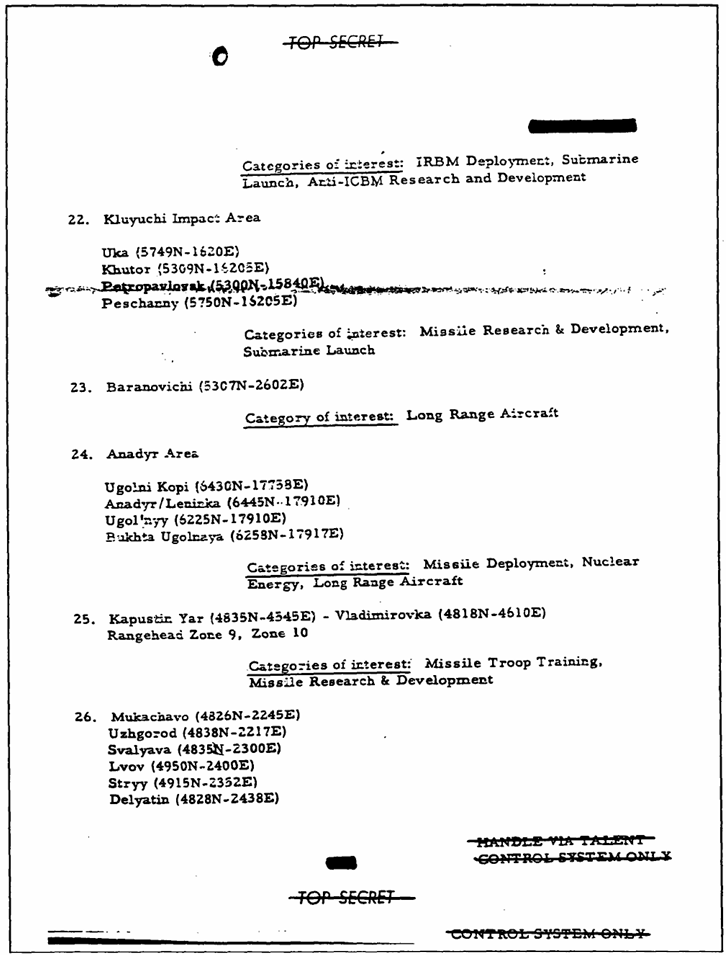

<div align="center">

*Figure 2.3.1: Sample Page - List of Highest Priority Targets, USSR*

</div>


In [ ]:
###  MOUNT GOOGLE DRIVE  ###
from google.colab import drive
drive.mount('/content/drive')

folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
df_TOC = pd.read_pickle(folder_path + 'df_TOC_OCR_complete.pkl')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import spacy
spacy = spacy.load("en_core_web_sm")

complete_text = ''
list_of_titles, sentence_count = [], []
for i in range(len(df_TOC)):
    spacy_doc = spacy(df_TOC.loc[i, 'string'])
    sentence_count.append(len([sentence for sentence in spacy_doc.sents]))
    complete_text = complete_text + df_TOC.loc[i, 'string']
    node_4_value = df_TOC.loc[i, 'Node_4']
    if pd.isna(node_4_value):
        list_of_titles.append(df_TOC.loc[i, 'File_name'])
    else:
        list_of_titles.append(df_TOC.loc[i, 'Node_4'])

complete_text = complete_text.replace('\n', ' ')
spacy_doc = spacy(complete_text)
entities = [entity.text for entity in spacy_doc.ents]
labels = [entity.label_ for entity in spacy_doc.ents]

df_NER = pd.DataFrame({'Entity': entities, 'Label': labels})
df_sentences = pd.DataFrame({'Doc_title': list_of_titles, 'Sentence_count': sentence_count})

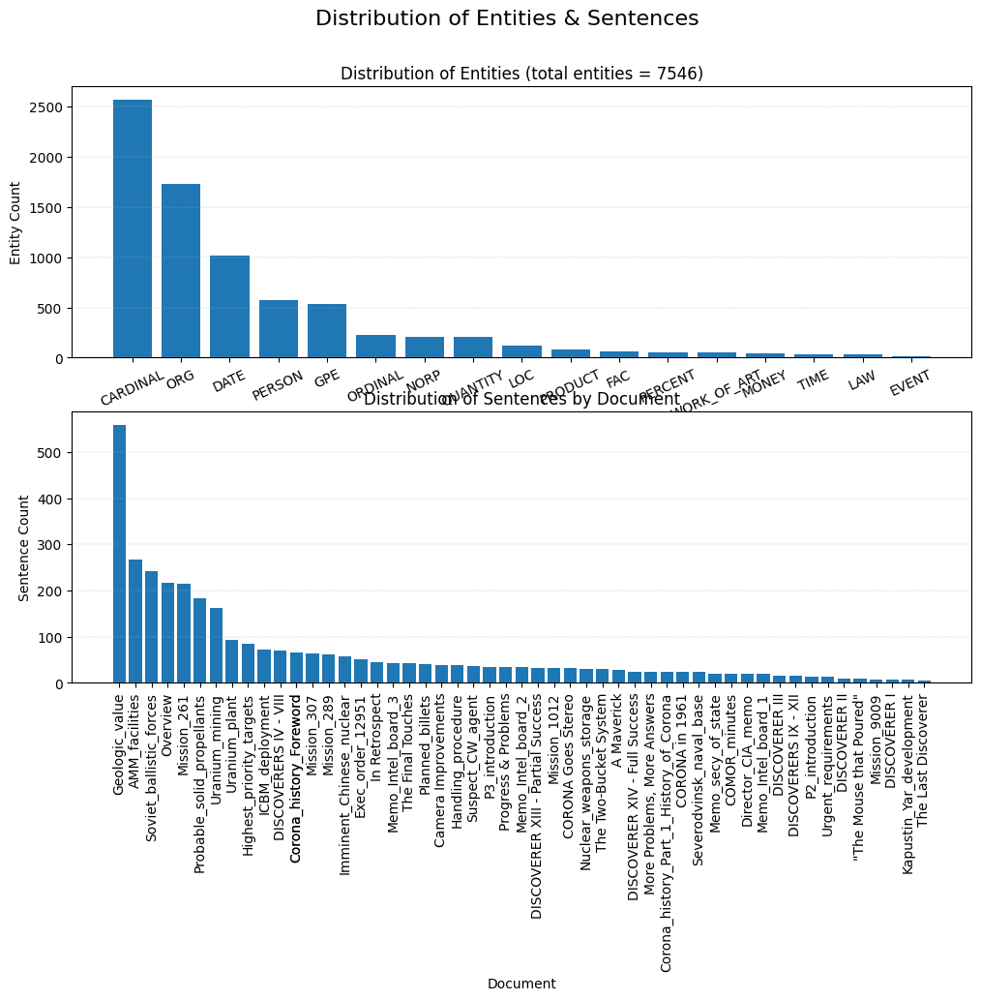

In [ ]:
fig, axes = plt.subplots(2, 1, figsize = (12, 8))
axes = axes.flatten()
plt.suptitle('Distribution of Entities & Sentences', fontsize = 16)

axes[0].bar(list(df_NER.groupby('Label').count().sort_values('Entity', ascending = False).index),
            df_NER.groupby('Label').count().sort_values('Entity', ascending = False)['Entity'])
axes[0].set_title(f'Distribution of Entities (total entities = {len(df_NER)})', fontsize = 12)
axes[0].set_xticks(list(df_NER.groupby('Label').count().sort_values('Entity', ascending = False).index))
axes[0].set_xticklabels(list(df_NER.groupby('Label').count().sort_values('Entity', ascending = False).index), rotation = 25)
axes[0].set_xlabel('Entity')
axes[0].set_ylabel('Entity Count')
axes[0].grid(axis = 'y', linestyle = '--', linewidth = 0.25)

axes[1].bar(df_sentences.sort_values('Sentence_count', ascending = False)['Doc_title'],
            df_sentences.sort_values('Sentence_count', ascending = False)['Sentence_count'])
axes[1].set_title(f'Distribution of Sentences by Document', fontsize = 12)
axes[1].set_xlabel('Document')
axes[1].set_ylabel('Sentence Count')
axes[1].set_xticks(list_of_titles)
axes[1].set_xticklabels(list_of_titles, rotation = 90)
axes[1].grid(axis = 'y', linestyle = '--', linewidth = 0.25);

<div align="center">

*Figure 2.3.2: Distribution of Named Entities & Sentences*

</div>


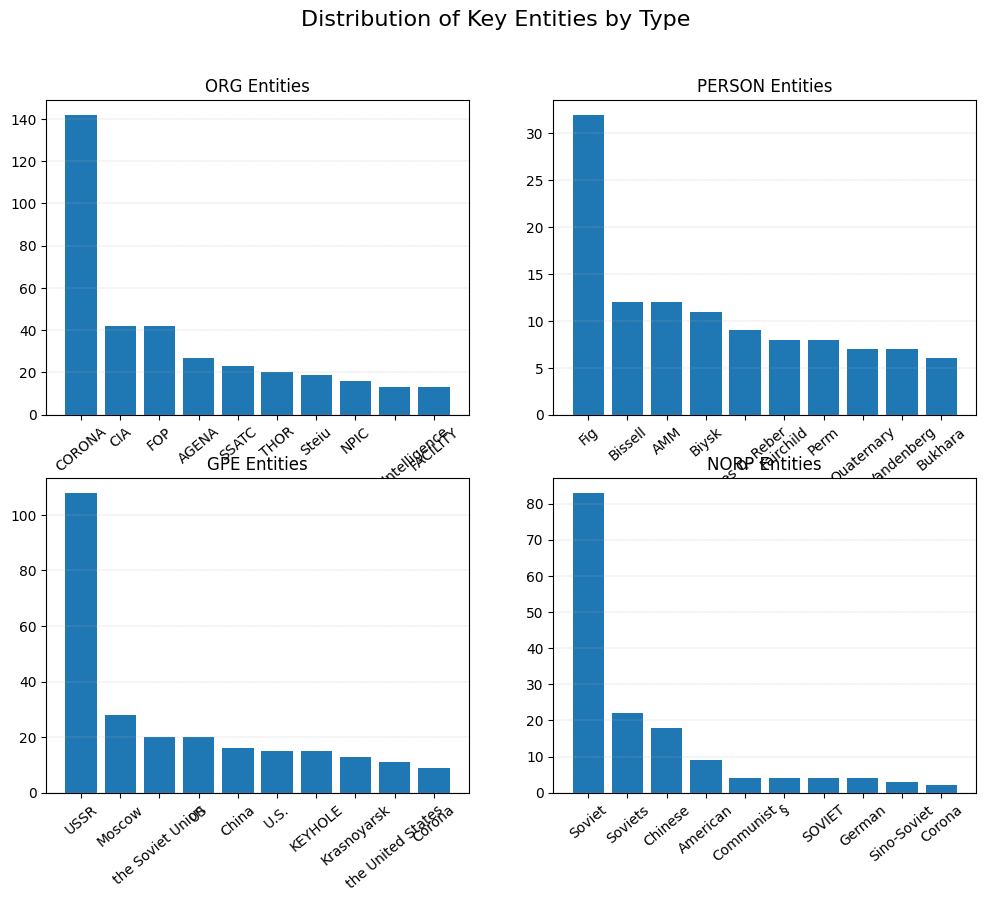

In [ ]:
fig, axes = plt.subplots(2, 2, figsize = (12, 9))
axes = axes.flatten()
plt.suptitle('Distribution of Key Entities by Type', fontsize = 16)

entities_of_interest = ['ORG', 'PERSON', 'GPE', 'NORP']
for i, entity in enumerate(entities_of_interest):
    x = list(df_NER[df_NER['Label'] == entity].groupby('Entity').count().sort_values('Label', ascending = False).index[0:10])
    y = df_NER[df_NER['Label'] == entity].groupby('Entity').count().sort_values('Label', ascending = False)['Label'][0:10]
    axes[i].bar(x, y)
    axes[i].set_title(f'{entity} Entities', fontsize = 12)
    axes[i].set_xticks(x, x, rotation = 40)
    axes[i].grid(axis = 'y', linestyle = '--', linewidth = 0.25);

<div align="center">

*Figure 2.3.3: Frequency of Named Entities - Organizational, Person, Geo-Political & Nationality*

</div>

<a id="REBEL"></a>

## 3.0 The REBEL Model

The **REBEL** model is a sequence-to-sequence model for end-to-end **R**elation **E**xtraction **B**y **End-to-end** **L**anguage generation that converts text into relation triplets, also known as *subject-relation-object triplets*.  The model was developed in 2021 and is available via the *Hugging Face* website$^3$.

REBEL is based on a *Bidirectional and Auto-Regressive Transformer* (BART) architecture and was trained on a large, "distantly supervised" dataset derived from Wikipedia and Wikidata.  The model frames relation extraction as a text generation problem, using its encoder/decoder architecture to produce output triplets directly from raw text (versus older approaches that relied on a pipeline of separate steps like named entity recognition followed by relation classification).  The model takes unstructured text as input, and produces a set of triplets in the format (head, relation type, tail), such as (Kennedy School of Government, part of, Harvard University).  REBEL is trained to extract relations of over 200 different types, and is commonly used for tasks including building knowledge graphs, populating knowledge bases, and fact-checking.  A complete description of REBEL can be found in the paper ***REBEL: Relation Extraction By End-to-end Language generation***$^4$ by Huguet Pere-Lluis Cabot and Roberto Navigli.

Section 3.1 immediately below instantiates the **REBEL** algorithm in a function.

The study employs two approaches to generate inputs to the REBEL model in Section 3.2.  The first approach relies on spaCy to perform sentence segmentation on the individual documents within the study corpus and provide those individual sentences to the REBEL algorithm for triplet extraction.  The second approach employs a "home-made" method to generate a list of *phrases* from the set of documents.  This home-made method is meant to be more "granular" and uses spaCy to identify named entities within the text.  A phrase is constituted as the text between two named entities (and includes the two entities).  This method frequently generates a larger number of phrases than sentences for a given document.

It should be noted the REBEL model was designed and trained as a *sentence-level* relationship extraction algorithm.  Sentence fragments - or phrases - may not contain elements of the relationship triplet or the necessary context to accurately produce the triplet.  Performance differences should be expected.

Section 4.2 below qualitatively explores these differences.

$^3$https://huggingface.co/Babelscape/rebel-large

$^4$https://github.com/Babelscape/rebel/blob/main/docs/EMNLP_2021_REBEL__Camera_Ready_.pdf


### 3.1 The REBEL Triplet Extraction Function

The code cell below defines the REBEL triplet extraction function to be called by subsequent cells in the study.

The code below is implemented from the Hugging Face wesite$^5$ with a small number of minor modifications.

$^5$https://huggingface.co/Babelscape/rebel-large

In [ ]:
# REBEL Relationship Extraction Function:
'''The function below returns relationship 'triplets' from a list of text strings.
Each triplet contains a 'head', relationship 'type', and a corresponding 'tail'.
'''

def REBEL_relationship_extractor(text):
    triplet_extractor = pipeline(
        'text2text-generation',
        model = 'Babelscape/rebel-large',
        tokenizer = 'Babelscape/rebel-large'
        )

    extracted_text_list = []
    for sentence in text:
        extracted_text_list.append(
            triplet_extractor.tokenizer.batch_decode(
                [triplet_extractor(sentence,
                                   return_tensors = True,
                                   return_text = False)[0]['generated_token_ids']]
                ))

    extracted_triplets_list = []
    for group in extracted_text_list:
        extracted_triplets_list.append(extract_triplets(group[0]))

    return extracted_triplets_list

# Function parses the generated text and extract the triplets:
def extract_triplets(text):
    triplets = []
    relation, subject, relation, object_ = '', '', '', ''
    text = text.strip()
    current = 'x'
    for token in text.replace("<s>", "").replace("<pad>", "").replace("</s>", "").split():
        if token == "<triplet>":
            current = 't'
            if relation != '':
                triplets.append({'head': subject.strip(), 'type': relation.strip(),'tail': object_.strip()})
                relation = ''
            subject = ''
        elif token == "<subj>":
            current = 's'
            if relation != '':
                triplets.append({'head': subject.strip(), 'type': relation.strip(),'tail': object_.strip()})
            object_ = ''
        elif token == "<obj>":
            current = 'o'
            relation = ''
        else:
            if current == 't':
                subject += ' ' + token
            elif current == 's':
                object_ += ' ' + token
            elif current == 'o':
                relation += ' ' + token
    if subject != '' and relation != '' and object_ != '':
        triplets.append({'head': subject.strip(), 'type': relation.strip(),'tail': object_.strip()})
    return triplets

### 3.2 Sentence & Phrase Extraction

Section 3.2.1 defines a function - *one_big_processor* - to parse document text (those produced in Sections 2.2.3 and 2.2.5) and wash those individual text strings through the REBEL function instantiated in Section 3.1 above.  The output of *one_big_processor* is stored in the *df_TOC* dataframe instantiated above.

The *one_big_processor* function returns two lists.  The first is simply a **list of sentences** parsed from the individual documents captured in *df_TOC*.  SpaCy is used to delineate these sentences.  The second output of *one_big_processor* is a **list of phrases**.  The phrases can be thought of as segments of the sentences with the boundaries of the phrases anchored in named entities identified by spaCy.  Each phrase contains all text appearing between named entities.

#### 3.2.1 One Big Processor Function

In [ ]:
def extract_text_between_words(text, start_word, end_word, start_idx = 0):
    try:
        start_index = text.index(start_word, start_idx)
        end_index = text.index(end_word, start_index)
        return text[start_index:end_index] + end_word, end_index
    except ValueError:
        return 'ERROR: Text not found'  # Return error message if words are not found

def one_big_processor(text_string, spacy):
    # Apply spaCy to identify entities:
    spacy_doc = spacy(text_string)

    # Create list of spaCy sentences existing in 'text_string':
    sentence_list = [sent.text for sent in spacy_doc.sents]

    # Create list of spaCy entities existing in 'text_string':
    entity_list = [entity.text for entity in spacy_doc.ents]

    # From 'entity_list', create a list of tuples of entities:
    entity_tuples_list = [(entity_list[i], entity_list[i+1]) for i in range(0, len(entity_list) - 1)]

    # From 'entity_tuples_list', create text phrases:
    '''
    The code calls the function above 'extract_text_between_words' to capture the
    text beginning with the first word (entity) in the tuple and ending with
    the second word in the tuple.
    '''

    text_phrases_list, idx_list = [], [0]
    for pair in entity_tuples_list:
        output = extract_text_between_words(text_string, pair[0], pair[1], idx_list[-1])
        idx_list.append(output[1])
        text_phrases_list.append(output[0])

    # Wash phrases through REBEL relationship extractor (Section 3.1):
    temp_text_string = text_string.replace('\n', ' ')
    print('  DOC STRING:', temp_text_string[0:50],
          '  COUNT OF SENTENCES:', len(sentence_list),
          '  COUNT OF PHRASES:', len(text_phrases_list))

    list_of_heads_sent, list_of_types_sent, list_of_tails_sent = [], [], []

    REBEL_output_sent = REBEL_relationship_extractor(sentence_list)
    for item in REBEL_output_sent:
        if len(item) > 0:
            list_of_heads_sent.append(item[0]['head'])
            list_of_types_sent.append(item[0]['type'])
            list_of_tails_sent.append(item[0]['tail'])
        else:
            list_of_heads_sent.append('')
            list_of_types_sent.append('')
            list_of_tails_sent.append('')

    list_of_heads_phrase, list_of_types_phrase, list_of_tails_phrase = [], [], []

    REBEL_output_phrase = REBEL_relationship_extractor(text_phrases_list)
    for item in REBEL_output_phrase:
        if len(item) > 0:
            list_of_heads_phrase.append(item[0]['head'])
            list_of_types_phrase.append(item[0]['type'])
            list_of_tails_phrase.append(item[0]['tail'])
        else:
            list_of_heads_phrase.append('')
            list_of_types_phrase.append('')
            list_of_tails_phrase.append('')

    return sentence_list, list_of_heads_sent, list_of_types_sent, list_of_tails_sent, \
           text_phrases_list, list_of_heads_phrase, list_of_types_phrase, list_of_tails_phrase


<a id="APPLICATION"></a>

## 4.0 Applying REBEL

Section 4.1 immediately below applies the functions in Section 3 and writes relationship triplet information to dataframe *df_TOC*.  As the model is computationally expensive - even when using Colab's GPU processing capabilities - the model is applied in "chunks" (subsets of individual documents).

Section 4.2 compares the outputs of sentence-based and phrase-based application of REBEL.

### 4.1 Apply in Chunks

The cells following apply the REBEL model in chunks.  The cell immediately following creates individual placeholder columns in dataframe *df_TOC* to receive the output relationship triplets.

Documents 0 - 10 are processed in the first "chunk", documents 10 - 20 in the second chunk and so on below.

In [ ]:
folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
df_TOC = pd.read_pickle(folder_path + 'df_TOC_OCR_complete.pkl')

# Initialize columns to hold lists as objects:
df_TOC['sentence_list'], df_TOC['list_of_heads_sent'], df_TOC['list_of_types_sent'], df_TOC['list_of_tails_sent'] = np.nan, np.nan, np.nan, np.nan
df_TOC['text_phrases_list'], df_TOC['list_of_heads_phrase'], df_TOC['list_of_types_phrase'], df_TOC['list_of_tails_phrase'] = np.nan, np.nan, np.nan, np.nan

df_TOC['sentence_list'] = df_TOC['sentence_list'].astype(object)
df_TOC['list_of_heads_sent'] = df_TOC['list_of_heads_sent'].astype(object)
df_TOC['list_of_types_sent'] = df_TOC['list_of_types_sent'].astype(object)
df_TOC['list_of_tails_sent'] = df_TOC['list_of_tails_sent'].astype(object)
df_TOC['text_phrases_list'] = df_TOC['text_phrases_list'].astype(object)
df_TOC['list_of_heads_phrase'] = df_TOC['list_of_heads_phrase'].astype(object)
df_TOC['list_of_types_phrase'] = df_TOC['list_of_types_phrase'].astype(object)
df_TOC['list_of_tails_phrase'] = df_TOC['list_of_tails_phrase'].astype(object)


Chunk 1: documents 0 to 10.

In [ ]:
# Build Lists of Heads, Tails & Relationships for each document:
import spacy
spacy = spacy.load("en_core_web_sm")

first_doc = 0
last_doc = 10

# Iterate through the desired rows and apply the function:
for i in range(first_doc, last_doc):
    print('PROCESSING DOCUMENT:', i, 'OF', last_doc)
    sentences, heads_sent, types_sent, tails_sent, text_phrases, heads_phrases, types_phrases, tails_phrases = one_big_processor(df_TOC['string'][i], spacy)
    df_TOC.at[i, 'sentence_list'] = sentences
    df_TOC.at[i, 'list_of_heads_sent'] = heads_sent
    df_TOC.at[i, 'list_of_types_sent'] = types_sent
    df_TOC.at[i, 'list_of_tails_sent'] = tails_sent
    df_TOC.at[i, 'text_phrases_list'] = text_phrases
    df_TOC.at[i, 'list_of_heads_phrase'] = heads_phrases
    df_TOC.at[i, 'list_of_types_phrase'] = types_phrases
    df_TOC.at[i, 'list_of_tails_phrase'] = tails_phrases

df_TOC.to_pickle(folder_path + 'df_TOC_extracted_trips.pkl')


PROCESSING DOCUMENT: 0 OF 10
  DOC STRING: Foreword  CORONA: America’s First Satellite Progra   COUNT OF SENTENCES: 14   COUNT OF PHRASES: 66


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 1 OF 10
  DOC STRING: Preface  CORONA: America’s First Satellite Program   COUNT OF SENTENCES: 66   COUNT OF PHRASES: 188


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 2 OF 10
  DOC STRING: Part I: History of the CORONA Program  After the C   COUNT OF SENTENCES: 24   COUNT OF PHRASES: 53


Device set to use cuda:0
Device set to use cuda:0


... (10 outputs left out)

PROCESSING DOCUMENT: 8 OF 10
  DOC STRING: DISCOVERERS IV-VII1  DISCOVERER IV on 25 June 1959   COUNT OF SENTENCES: 70   COUNT OF PHRASES: 90


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 9 OF 10
  DOC STRING: DISCOVERERS IX-X11  A standdown was in effect in C   COUNT OF SENTENCES: 15   COUNT OF PHRASES: 28


Device set to use cuda:0
Device set to use cuda:0


Chunk 2: documents 10 to 20.

In [ ]:
# Build Lists of Heads, Tails & Relationships for each document:
import spacy
spacy = spacy.load("en_core_web_sm")

folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
# df_TOC = pd.read_pickle(folder_path + 'df_TOC_extracted_trips.pkl')

first_doc = 10
last_doc = 20

# Iterate through the desired rows and apply the function:
for i in range(first_doc, last_doc):
    print('PROCESSING DOCUMENT:', i, 'OF', last_doc - 1)
    sentences, heads_sent, types_sent, tails_sent, text_phrases, heads_phrases, types_phrases, tails_phrases = one_big_processor(df_TOC['string'][i], spacy)
    df_TOC.at[i, 'sentence_list'] = sentences
    df_TOC.at[i, 'list_of_heads_sent'] = heads_sent
    df_TOC.at[i, 'list_of_types_sent'] = types_sent
    df_TOC.at[i, 'list_of_tails_sent'] = tails_sent
    df_TOC.at[i, 'text_phrases_list'] = text_phrases
    df_TOC.at[i, 'list_of_heads_phrase'] = heads_phrases
    df_TOC.at[i, 'list_of_types_phrase'] = types_phrases
    df_TOC.at[i, 'list_of_tails_phrase'] = tails_phrases

df_TOC.to_pickle(folder_path + 'df_TOC_extracted_trips.pkl')


PROCESSING DOCUMENT: 10 OF 19
  DOC STRING: DISCOVERER Xll—Partial Success      The next fligh   COUNT OF SENTENCES: 33   COUNT OF PHRASES: 45


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 11 OF 19
  DOC STRING: DISCOVERER XIV—Full Success  Success! |! DISCOVERE   COUNT OF SENTENCES: 24   COUNT OF PHRASES: 36


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 12 OF 19
  DOC STRING: Progress and Problems  The program officers did no   COUNT OF SENTENCES: 35   COUNT OF PHRASES: 46


Device set to use cuda:0
Device set to use cuda:0


... (10 outputs left out)

PROCESSING DOCUMENT: 18 OF 19
  DOC STRING: The Two-Bucket System  Program flight number 69, l   COUNT OF SENTENCES: 30   COUNT OF PHRASES: 57


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 19 OF 19
  DOC STRING: A Maverick  The CORONA camera system was to underg   COUNT OF SENTENCES: 28   COUNT OF PHRASES: 70


Device set to use cuda:0
Device set to use cuda:0


Chunk 3: documents 20 to 40.

In [ ]:
# Build Lists of Heads, Tails & Relationships for each document:
import spacy
spacy = spacy.load("en_core_web_sm")

folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
# df_TOC = pd.read_pickle(folder_path + 'df_TOC_extracted_trips.pkl')

first_doc = 20
last_doc = 40

# Iterate through the desired rows and apply the function:
for i in range(first_doc, last_doc):
    print('PROCESSING DOCUMENT:', i, 'OF', last_doc - 1)
    sentences, heads_sent, types_sent, tails_sent, text_phrases, heads_phrases, types_phrases, tails_phrases = one_big_processor(df_TOC['string'][i], spacy)
    df_TOC.at[i, 'sentence_list'] = sentences
    df_TOC.at[i, 'list_of_heads_sent'] = heads_sent
    df_TOC.at[i, 'list_of_types_sent'] = types_sent
    df_TOC.at[i, 'list_of_tails_sent'] = tails_sent
    df_TOC.at[i, 'text_phrases_list'] = text_phrases
    df_TOC.at[i, 'list_of_heads_phrase'] = heads_phrases
    df_TOC.at[i, 'list_of_types_phrase'] = types_phrases
    df_TOC.at[i, 'list_of_tails_phrase'] = tails_phrases

df_TOC.to_pickle(folder_path + 'df_TOC_extracted_trips.pkl')


PROCESSING DOCUMENT: 20 OF 39
  DOC STRING: The Final Touches  The fina] major modification of   COUNT OF SENTENCES: 43   COUNT OF PHRASES: 46


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 21 OF 39
  DOC STRING: In Retrospect  Looking back on CORONA, it is not a   COUNT OF SENTENCES: 44   COUNT OF PHRASES: 118


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 22 OF 39
  DOC STRING: --- Page 1 --- Part II: The Committee on Overhead    COUNT OF SENTENCES: 14   COUNT OF PHRASES: 57


Device set to use cuda:0
Device set to use cuda:0


... (30 outputs left out)

PROCESSING DOCUMENT: 38 OF 39
  DOC STRING: --- Page 1 --- 17. (Continued)  REGIONAL NUCLEAR W   COUNT OF SENTENCES: 31   COUNT OF PHRASES: 79


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 39 OF 39
  DOC STRING: --- Page 1 --- 18. (Continued)  SEARCH FOR URANIUM   COUNT OF SENTENCES: 162   COUNT OF PHRASES: 221


Device set to use cuda:0
Device set to use cuda:0


Chunk 4: documents 40 to 51.

In [ ]:
# Build Lists of Heads, Tails & Relationships for each document:
import spacy
spacy = spacy.load("en_core_web_sm")

folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
# df_TOC = pd.read_pickle(folder_path + 'df_TOC_extracted_trips.pkl')

first_doc = 40
last_doc = len(df_TOC)

# Iterate through the desired rows and apply the function:
for i in range(first_doc, last_doc):
    print('PROCESSING DOCUMENT:', i, 'OF', last_doc - 1)
    sentences, heads_sent, types_sent, tails_sent, text_phrases, heads_phrases, types_phrases, tails_phrases = one_big_processor(df_TOC['string'][i], spacy)
    df_TOC.at[i, 'sentence_list'] = sentences
    df_TOC.at[i, 'list_of_heads_sent'] = heads_sent
    df_TOC.at[i, 'list_of_types_sent'] = types_sent
    df_TOC.at[i, 'list_of_tails_sent'] = tails_sent
    df_TOC.at[i, 'text_phrases_list'] = text_phrases
    df_TOC.at[i, 'list_of_heads_phrase'] = heads_phrases
    df_TOC.at[i, 'list_of_types_phrase'] = types_phrases
    df_TOC.at[i, 'list_of_tails_phrase'] = tails_phrases

df_TOC.to_pickle(folder_path + 'df_TOC_extracted_trips.pkl')


PROCESSING DOCUMENT: 40 OF 51
  DOC STRING: --- Page 1 --- 19. (Continued)  SUSPECT CW AGENT P   COUNT OF SENTENCES: 36   COUNT OF PHRASES: 61


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 41 OF 51
  DOC STRING: --- Page 1 --- 20. (Continued)  CHRONOLOGICAL DEVE   COUNT OF SENTENCES: 7   COUNT OF PHRASES: 14


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 42 OF 51
  DOC STRING: --- Page 1 --- 21. (Continued)  CENTRAL INTELLIGEN   COUNT OF SENTENCES: 183   COUNT OF PHRASES: 761


Device set to use cuda:0
Device set to use cuda:0


... (14 outputs left out)

PROCESSING DOCUMENT: 50 OF 51
  DOC STRING: --- Page 1 --- Part IV: Nonmilitary Uses for Satel   COUNT OF SENTENCES: 559   COUNT OF PHRASES: 809


Device set to use cuda:0
Device set to use cuda:0


PROCESSING DOCUMENT: 51 OF 51
  DOC STRING: --- Page 1 --- Appendix: Executive Order 12951, Re   COUNT OF SENTENCES: 52   COUNT OF PHRASES: 61


Device set to use cuda:0
Device set to use cuda:0


### 4.2 Sentence vs. Phrase-Based Triplets

Section 4.2 qualitatively explores the differences in relationship triplets using sentenced-based inputs versus phrase-based inputs.  The exploration is applied to the *Foreword* of the subject corpus.  It should be noted that multiple iterations of a phrase-based approach were explored.  Those iterations focused on including some entity classes and not including others.  These alternate approaches were feasible but did not appear to add significant value given the time-constraints on the study.  In the end, the phrase-based methodology presented here includes ALL named entity types.

For each sentence in the *Foreword*:
- The sentence is printed
- The sentence-based triplet is printed
- The phrase-based triplet is printed

For example, the first sentence:

*Foreword*

*CORONA: America’s First Satellite Program*

*Since the CORONA satellite made its first successful flight in August 1960,
the Intelligence Community’s overhead reconnaissance programs have been
among the nation’s most closely guarded secrets.*

The following triplet is extracted:
- HEADS: CORONA
- TYPES: service entry
- TAILS: August 1960

The same sentence yields four phrases and the following triplets:
- PHRASE 1: *Foreword CORONA*
- HEADS: Foreword
- TYPES: part of
- TAILS: CORONA
- PHRASE 2: *CORONA: America’s First Satellite Program Since the CORONA satellite made its first*
- HEADS: CORONA
- TYPES: part of
- TAILS: America’s First Satellite Program
- PHRASE 3: *first successful flight in August 1960*
- HEADS: August 1960
- TYPES: point in time
- TAILS: August 1960
- PHRASE 4: *August 1960, the Intelligence Community’s*
- HEADS: August 1960
- TYPES: point in time
- TAILS: August 1960

Takeaways - Sentences vs. Phrases:
1.  First and perhaps most importantly, the phrase-based implementation provides significantly more information versus the sentence-based implementation - at least for the *Foreword*.  In some cases, however, the phrase-based implementation produces "non-information" - a triplet that essentially contains limited or no information.  One such example:
  - HEADS: August 1960
  - TYPES: point in time
  - TAILS: August 1960

One might postulate that the style of writing exhibited in the subject corpus - including the *Foreword* is relatively sophisticated or advanced in that it is frequently typified by compound sentences constructed of multiple clauses expressing relatively nuanced information.  One might further postulate that as a result, distilling such a sentence into a single triplet will necessarily miss some information.

2. It is possible a "goldilocks" approach can find the optimum split of capturing the information contained in the sentence while avoiding so-called non-information.  As described above, a small number of attempts were made to limit the number of entity types included in the formation of phrases (e.g., choosing to NOT include *CARDINAL* entities when discerning phrases).  The time-constraints imposed by the semester precluded fine-tuning this approach, but it is certainly conceivable an optimized methodology could be found to improve triplet extraction.

3. Training the REBEL model: the model clearly produces inaccurate triplets occasionally - this includes missing key information, and inaccurately describing the relationship between heads and tails.  This is true of both sentenced-based and phrase-based approaches.  It is possible training the REBEL model against a subset of the corpus could improve performance.

4.  The model does not work well for some documents in the corpus.  An example document is the aforementioned *List of Highest Priority Targets, USSR, James Q. Reber, 18 August 1960*.  This document is largely composed of tabular data - not sentences.

Section 5 below further compares approaches in constructing **network graphs** of the relationship triplets.

In [ ]:
counter = 0
for i in range(2):
    for j in range(5):
        counter = counter + 1
        print(f'SENTENCE: {counter}\n', df_TOC['sentence_list'][i][j], '\n')
        print('--- SENTENCE-BASED APPLICATION ---')
        print('HEADS:', df_TOC['list_of_heads_sent'][i][j],
              '\nTYPES:', df_TOC['list_of_types_sent'][i][j],
              '\nTAILS:', df_TOC['list_of_tails_sent'][i][j], '\n')
        print('--- PHRASE-BASED APPLICATION ---')
        for m in range(len(df_TOC['text_phrases_list'][i])):
            if df_TOC['text_phrases_list'][i][m] in df_TOC['sentence_list'][i][j]:
                print('PHRASE:', df_TOC['text_phrases_list'][i][m])
                print('HEADS:', df_TOC['list_of_heads_phrase'][i][m],
                      '\nTYPES:', df_TOC['list_of_types_phrase'][i][m],
                      '\nTAILS:', df_TOC['list_of_tails_phrase'][i][m], '\n')


SENTENCE: 1
 Foreword

CORONA: America’s First Satellite Program

Since the CORONA satellite made its first successful flight in August 1960,
the Intelligence Community’s overhead reconnaissance programs have been
among the nation’s most closely guarded secrets. 

--- SENTENCE-BASED APPLICATION ---
HEADS: CORONA 
TYPES: service entry 
TAILS: August 1960 

--- PHRASE-BASED APPLICATION ---
PHRASE: Foreword

CORONA
HEADS: Foreword 
TYPES: part of 
TAILS: CORONA 

PHRASE: CORONA: America’s First Satellite Program

Since the CORONA satellite made its first
HEADS: CORONA 
TYPES: part of 
TAILS: America’s First Satellite Program 

PHRASE: first successful flight in August 1960
HEADS: August 1960 
TYPES: point in time 
TAILS: August 1960 

PHRASE: August 1960,
the Intelligence Community’s
HEADS: August 1960 
TYPES: point in time 
TAILS: August 1960 

SENTENCE: 2
 The end of the Cold War,
however, has at last made it possible to declassify both information and
imagery from the first American sa

<a id="graphs"></a>

## 5.0 REBEL-Based Mind Maps

Section 5 presents mind maps generated using the REBEL-generated relationship triplets.  Section 5.1 below instantiates the *network_graph_builder* function used to create individual graphs.

### 5.1 Graph Builder Function

Section 5.1 instantiates a network graph (i.e., mind maps) building function given the relationship triplet inputs produced above.  The function produces graphs with the following attributes:

- Graph **nodes** correspond to groupings of common heads and their corresponding tails and relationship types.  In other words, all heads *CORONA*, for example, extracted from a specified set of documents will be consolidated into a single node.  That node will also contain each of *CORONA's* relationship tails and relationship types.
- Graph **edges** represent the shared tails of nodes.  If, for example, the heads *CORONA* and *U-2* both tails *Soviet Union*, they will be connected by an edge named *Soviet Union*.
- Up to 3 individual documents from the corpus can be included in any single graph.
- The function supports creating network graphs using **sentence-based** or **phrase-based** relationship triplets.


In [ ]:
###  MOUNT GOOGLE DRIVE  ###
from google.colab import drive
drive.mount('/content/drive')

folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
df_TOC = pd.read_pickle(folder_path + 'df_TOC_extracted_trips.pkl')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def network_graph_builder(df, doc_name_1, doc_name_2, doc_name_3, inputs, font, scale):
    # Create a subset of the input dataframe that includes only the document of interest:
    if inputs == 'sentences':
        df_subset = df[(df['File_name'] == doc_name_1) |
                       (df['File_name'] == doc_name_2) |
                        (df['File_name'] == doc_name_3)][
            ['sentence_list', 'list_of_heads_sent', 'list_of_types_sent', 'list_of_tails_sent']]

        subset_dict = {'Head': list(itertools.chain.from_iterable(df_subset['list_of_heads_sent'])),
                       'Type': list(itertools.chain.from_iterable(df_subset['list_of_types_sent'])),
                       'Tail': list(itertools.chain.from_iterable(df_subset['list_of_tails_sent'])),
                       'Phrases': list(itertools.chain.from_iterable(df_subset['sentence_list']))
                       }

    elif inputs == 'phrases':
        df_subset = df[(df['File_name'] == doc_name_1) |
                       (df['File_name'] == doc_name_2) |
                       (df['File_name'] == doc_name_3)][
            ['text_phrases_list', 'list_of_heads_phrase', 'list_of_types_phrase', 'list_of_tails_phrase']]

        subset_dict = {'Head': list(itertools.chain.from_iterable(df_subset['list_of_heads_phrase'])),
                       'Type': list(itertools.chain.from_iterable(df_subset['list_of_types_phrase'])),
                       'Tail': list(itertools.chain.from_iterable(df_subset['list_of_tails_phrase'])),
                       'Phrases': list(itertools.chain.from_iterable(df_subset['text_phrases_list']))
                       }

    else:
        print('PLEASE SELECT SENTENCES OR PHRASES')
        return

    REBEL_output_df = pd.DataFrame(subset_dict)

    # Create a list of 'tails' that appear multiple times:
    multi_tail_list = []
    for i in range(len(sorted(REBEL_output_df['Tail'].to_list())) - 1):
        if sorted(REBEL_output_df['Tail'].to_list())[i] == sorted(REBEL_output_df['Tail'].to_list())[i+1]:
            multi_tail_list.append(sorted(REBEL_output_df['Tail'].to_list())[i])
    multi_tail_list = set(multi_tail_list)

    ''' Consolidate Heads and Create Nodes with Text'''
    # Node item list is a list of 'heads' from the extracted triplets
    # The node details list is the list of associated details
    node_item_list, node_details_list = [], []
    for item in REBEL_output_df['Head'].unique():
        node_item_list.append(item)
        node_details_list.append(
            (item, REBEL_output_df[REBEL_output_df['Head'] == item]
            [['Type', 'Tail']].drop_duplicates().sort_values('Type').values))

    # Convert the nodes and details to strings:
    node_string_list = []

    for item in node_details_list:
        source_string = str(item[0]) + '\n'
        for item2 in item[1]:
            source_string = source_string + str(item2[0]) + ': ' + str(item2[1]) + '\n'

        node_string_list.append(source_string)

    # Create list of Connected Pairs with Expanded Text:
    all_test_pairs = []
    for connecting_tail in list(multi_tail_list):
        list_of_connected_heads = []

        for i, tail in zip(range(len(REBEL_output_df)), REBEL_output_df['Tail']):
            if tail == connecting_tail:
                list_of_connected_heads.append(REBEL_output_df.loc[i, 'Head'])

        test_pairs = []
        for head in list_of_connected_heads:
            for node in node_string_list:
                if head in node:
                    head = node
                    test_pairs.append((head, connecting_tail))

        all_test_pairs.append(test_pairs)

    G = nx.Graph()

    edge_labels = {}
    for group in all_test_pairs:
        for pair in group:
            G.add_node(pair[0])
            G.add_node(pair[1])
            G.add_edge(pair[0], pair[1], color = 'red')
            edge_labels[(pair[0], pair[1])] = pair[1]

    node_sizes = []
    for node in G.nodes():
        if '\n' in node:
            node_sizes.append(0)
        else:
            label_length = len(node)
            size = 200 + (label_length * 40)
            node_sizes.append(size)

    node_colors = []
    for node in G.nodes():
        if '\n' in node:
            node_colors.append('none')
        else:
            node_colors.append('pink')

    plt.figure(figsize = (20, 20))

    # pos = nx.shell_layout(G)
    # pos = nx.spectral_layout(G)
    pos = nx.kamada_kawai_layout(G, scale = scale)
    nx.draw(G,
            pos = pos,
            with_labels = False,
            node_color = node_colors,
            node_shape = 's',
            node_size = node_sizes,
            font_size = font,
            edge_color = 'red',
            width = 2
            )
    nx.draw_networkx_edge_labels(G,
                                 pos = pos,
                                 edge_labels = edge_labels,
                                 font_size = font + 2
                                 )
    nx.draw_networkx_labels(G,
                            pos,
                            font_size = font,
                            font_family = 'sans-serif',
                            font_color = 'black',
                            font_weight = 'normal',
                            alpha = 1,
                            bbox = dict(facecolor = 'skyblue', edgecolor = 'black', boxstyle = 'round,pad = 0.4'))


    plt.title('Network Graph from DataFrame', fontsize = 26)
    plt.tight_layout()
    plt.show();

### 5.2 Creating Maps

The following five sub-sctions create mind maps using REBEL-generated outputs.  Each of the sub-sections below contains a map first using sentences as input, and second using phrases as input.

Qualitatively, two conclusions are drawn from the maps:

1. First, the maps constructed using relationship triplets generated from phrase inputs contain incremental information relative to those generated using sentences.
2. While that additional information is unique and often useful, it is sometimes *non-information*.  Multiple examples are clearly visible in some of the maps below of inaccurately identified heads, tails, and relationship types.

Given the two options of sentences versus phrases for input, ***sentences*** are clearly preferred.  This is perhaps not surprising given that the REBEL model was trained using sentences.

#### 5.2.1 Documents: Chapters of Part 1

The following two graphs use sentence-based inputs (Figure 5.2.1) and phrase-based inputs (Figure 5.2.2) from multiple chapters in the History of Corona document.

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12504 (\N{KATAKANA LETTER HE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12521 (\N{KATAKANA LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


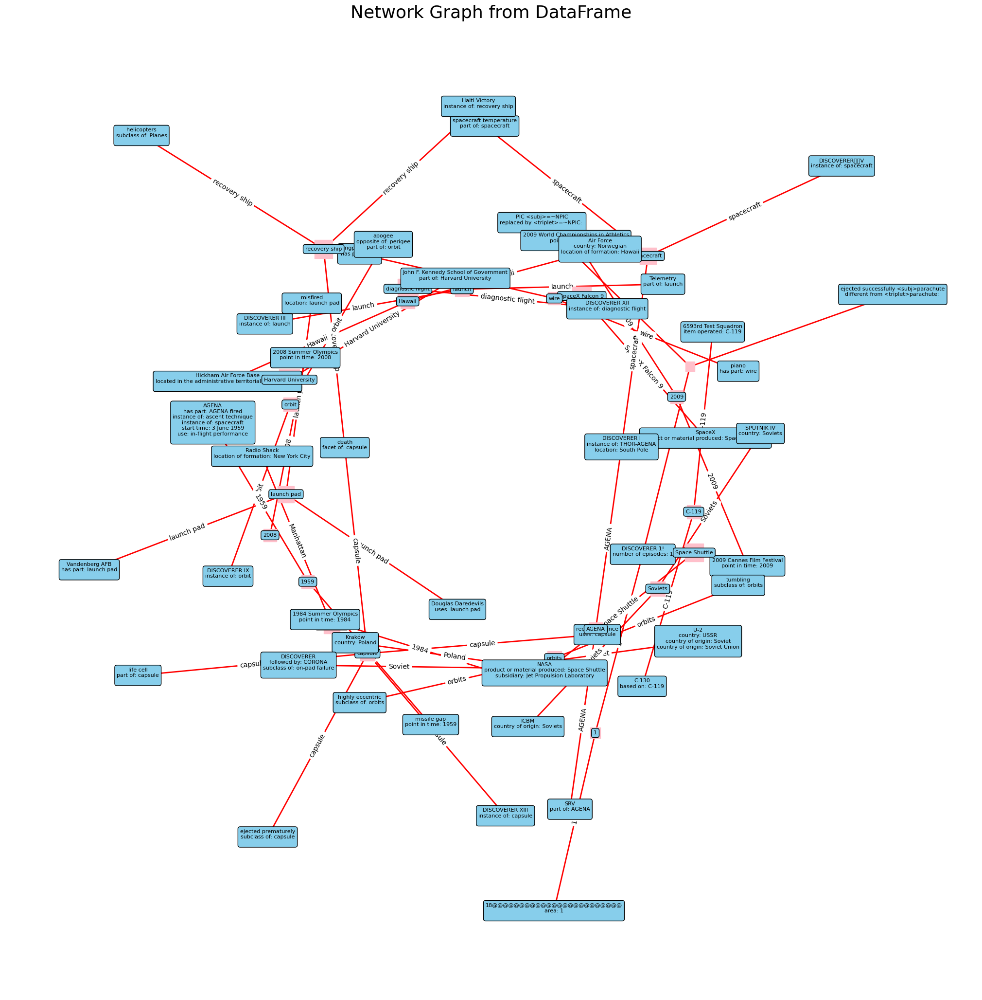

In [ ]:
source = df_TOC
document_1 = 'Greer_Studies_in_Intelligence_part_3'
document_2 = None
document_3 = None
input_type = 'sentences'

network_graph_builder(source, document_1, document_2, document_3, input_type, 8, 1)


<div align="center">

*Figure 5.2.1: Network Graph - Chapters of Part 1 (Sentences)*

</div>

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12471 (\N{KATAKANA LETTER SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12517 (\N{KATAKANA LETTER SMALL YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


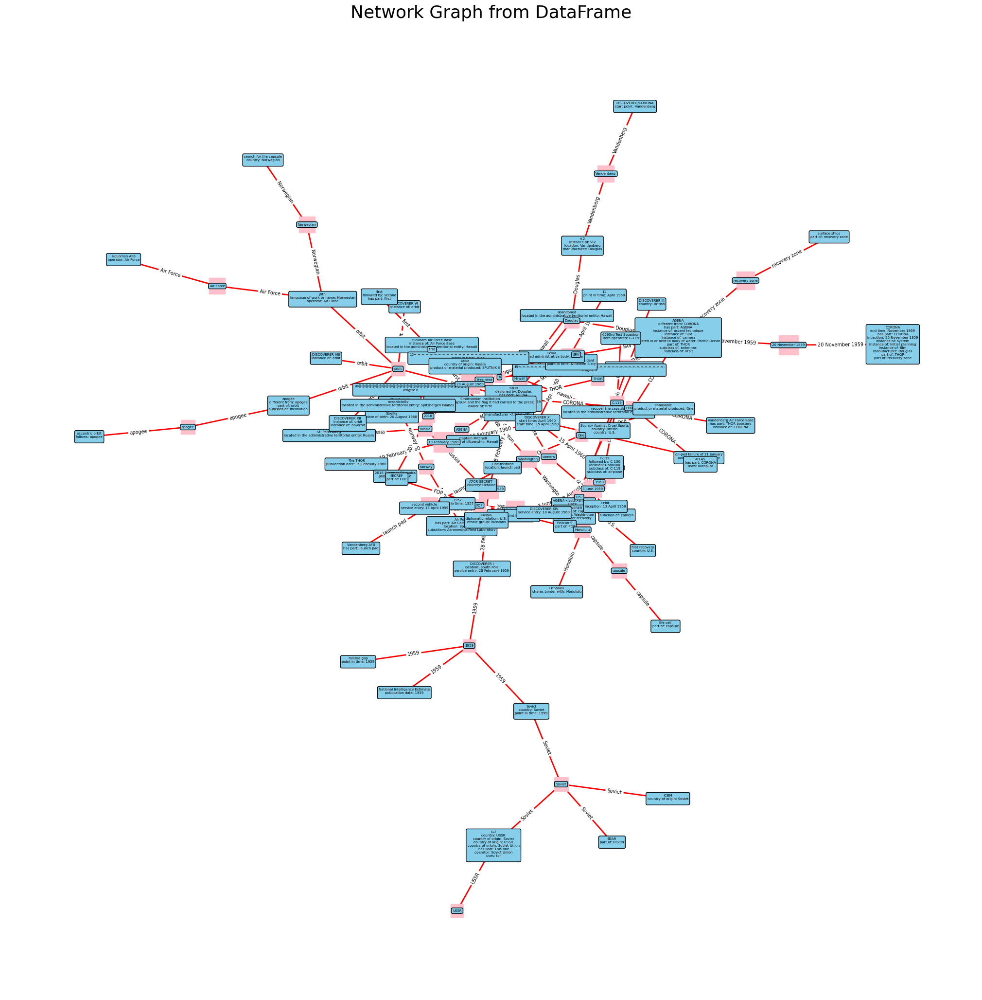

In [ ]:
source = df_TOC
document_1 = 'Greer_Studies_in_Intelligence_part_3'
document_2 = None
document_3 = None
input_type = 'phrases'

network_graph_builder(source, document_1, document_2, document_3, input_type, 5, 1)


<div align="center">

*Figure 5.2.2: Network Graph - Chapters of Part 1 (Phrases)*

</div>

#### 5.2.2 Document: "Strength and Deployment of Soviet Long Range Ballistic Missile Forces"

Similar to the sub-section immediately above, Section 5.2.2 creates two maps using the document *Strength and Deployment of Soviet Long Range Ballistic Missile Forces, National Intelligence Estimate, 11-8/1-61, 21 September 1961* as input.

The following two graphs use sentence-based inputs (Figure 5.2.3) and phrase-based inputs (Figure 5.2.4).

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35064 (\N{CJK UNIFIED IDEOGRAPH-88F8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


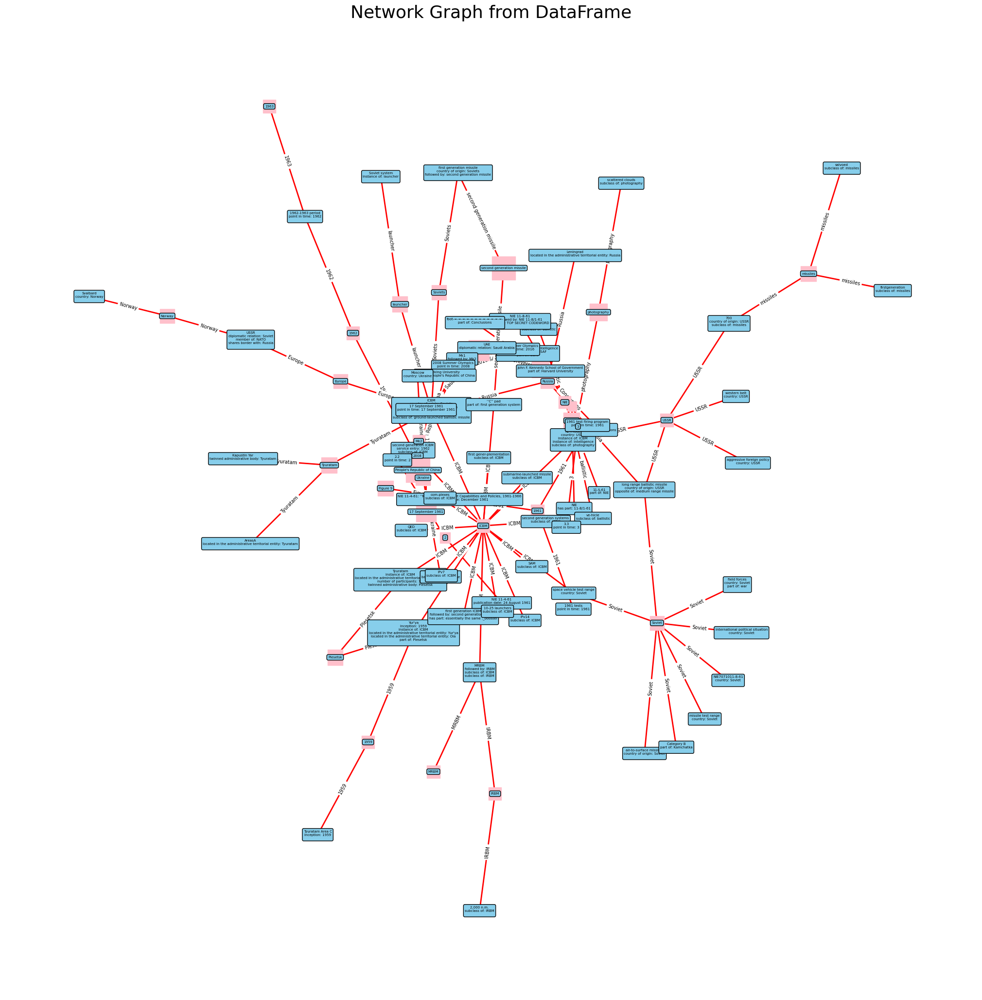

In [ ]:
source = df_TOC
document_1 = 'Soviet_ballistic_forces'
document_2 = None
document_3 = None
input_type = 'sentences'

network_graph_builder(source, document_1, document_2, document_3, input_type, 5, 1)


<div align="center">

*Figure 5.2.3: Network Graph - Strength and Deployment of Soviet Long Range Ballistic Missile Forces (Sentences)*

</div>

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


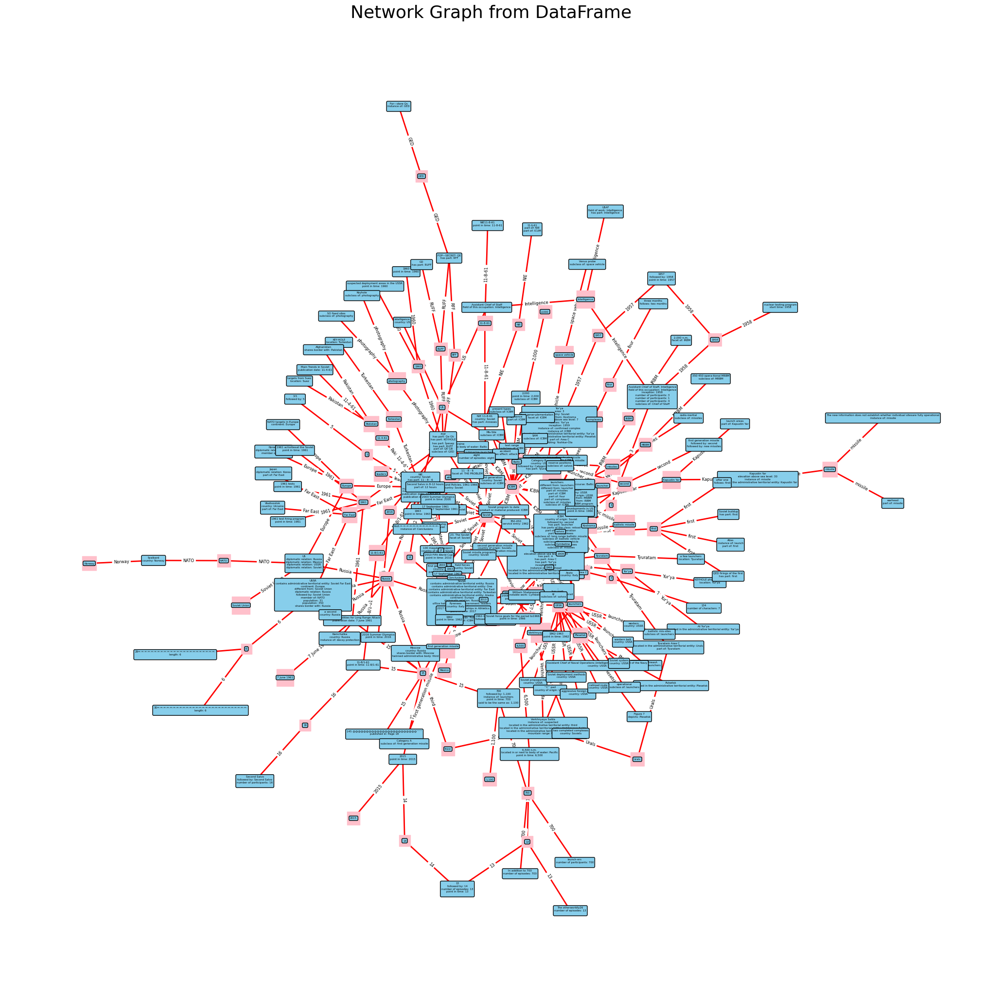

In [ ]:
source = df_TOC
document_1 = 'Soviet_ballistic_forces'
document_2 = None
document_3 = None
input_type = 'phrases'

network_graph_builder(source, document_1, document_2, document_3, input_type, 4, 1)


<div align="center">

*Figure 5.2.4: Network Graph - Strength and Deployment of Soviet Long Range Ballistic Missile Forces (Phrases)*

</div>

#### 5.2.3 Document: "Comparison of 215 Possible AMM-Associated Facilities at Moscow and Sary-Shagan, USSR"

Section 5.2.3 creates two maps using the document *Comparison of 215 Possible AMM-Associated Facilities at Moscow and Sary-Shagan, USSR* as input.  For information, AMM stands for *anti-missile missile*.

The following two graphs use sentence-based inputs (Figure 5.2.5) and phrase-based inputs (Figure 5.2.6).

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35064 (\N{CJK UNIFIED IDEOGRAPH-88F8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


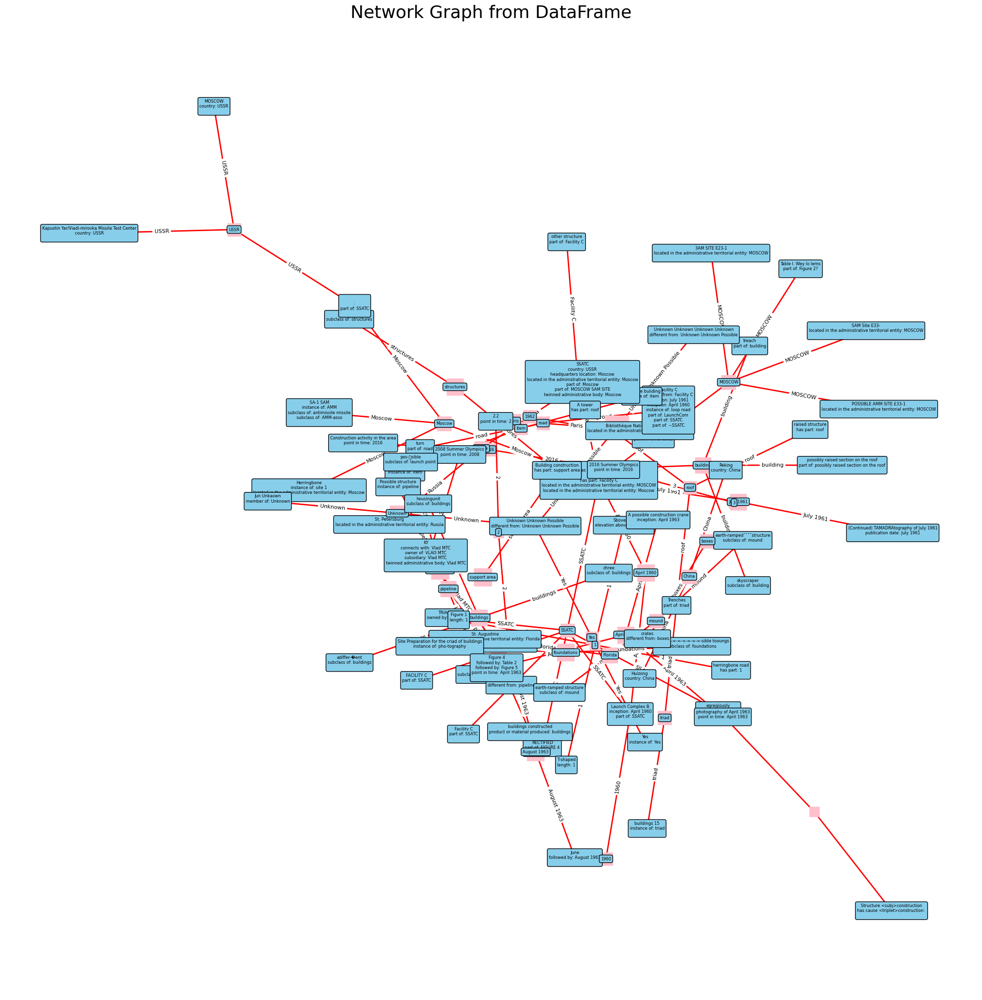

In [ ]:
source = df_TOC
document_1 = 'AMM_facilities'
document_2 = None
document_3 = None
input_type = 'sentences'

network_graph_builder(source, document_1, document_2, document_3, input_type, 6, 1)


<div align="center">

*Figure 5.2.5: Network Graph - Comparison of 215 Possible AMM-Associated Facilities at Moscow and Sary-Shagan, USSR (Sentences)*

</div>

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24049 (\N{CJK UNIFIED IDEOGRAPH-5DF1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24066 (\N{CJK UNIFIED IDEOGRAPH-5E02}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12509 (\N{KATAKANA LETTER PO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12540 (\N{KATAKANA-HIRAGANA PROLONGED SOUND MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


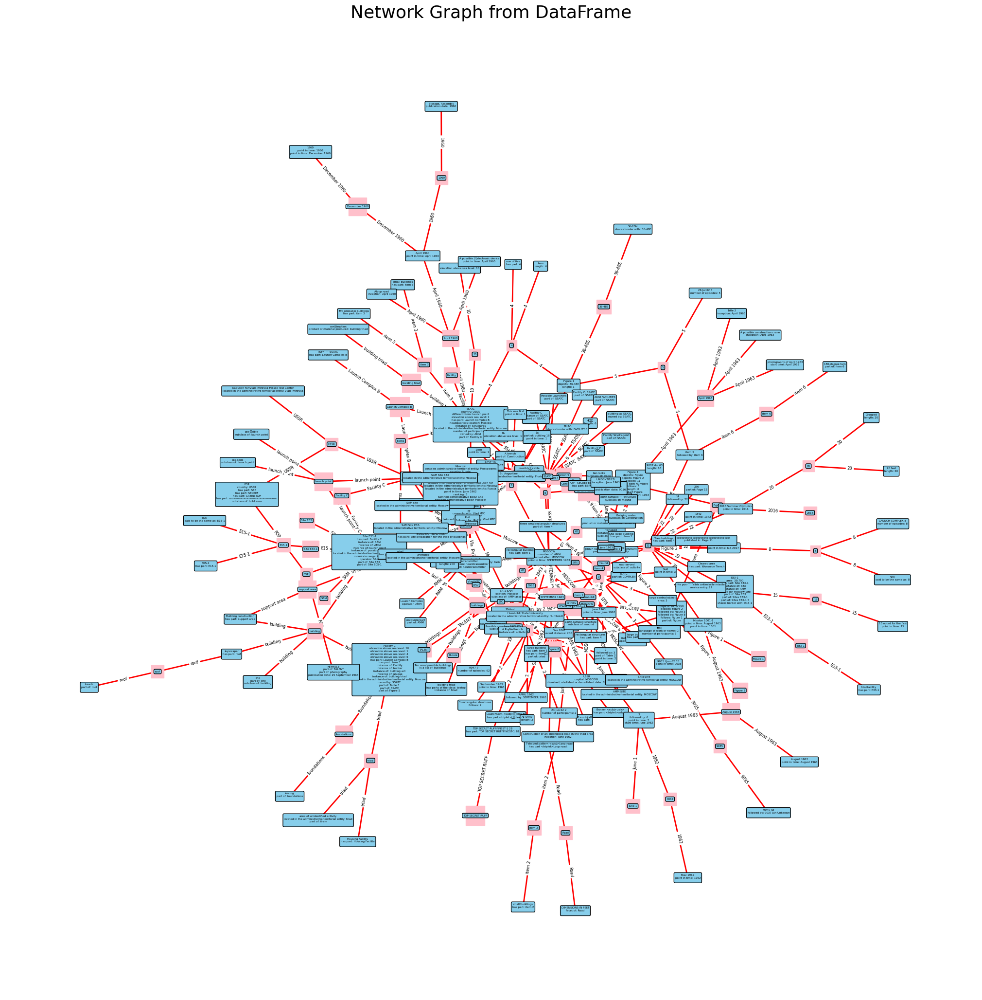

In [ ]:
source = df_TOC
document_1 = 'AMM_facilities'
document_2 = None
document_3 = None
input_type = 'phrases'

network_graph_builder(source, document_1, document_2, document_3, input_type, 4, 1)


<div align="center">

*Figure 5.2.6: Network Graph - Comparison of 215 Possible AMM-Associated Facilities at Moscow and Sary-Shagan, USSR (Phrases)*

</div>

#### 5.2.4 Documents: Select Chapters of Part 1

Section 5.2.4 creates two maps using selected chapters from the document *History of CORONA Program* as input.

The following two graphs use sentence-based inputs (Figure 5.2.7) and phrase-based inputs (Figure 5.2.8).

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


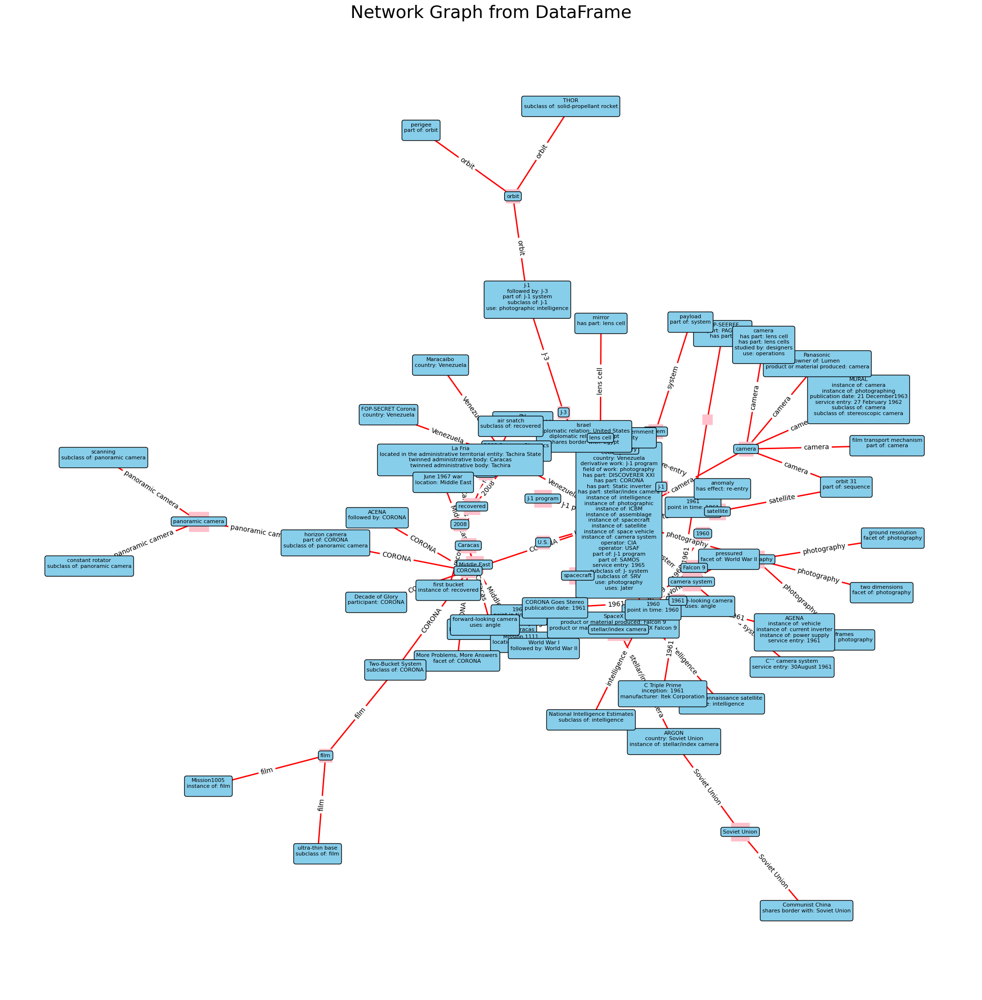

In [ ]:
source = df_TOC
document_1 = 'Greer_Studies_in_Intelligence_part_5'
document_2 = 'Greer_Studies_in_Intelligence_part_6'
document_3 = None
input_type = 'sentences'

network_graph_builder(source, document_1, document_2, document_3, input_type, 8, 1)


<div align="center">

*Figure 5.2.7: Network Graph - Chapters of Part 1 (Sentences)*

</div>

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


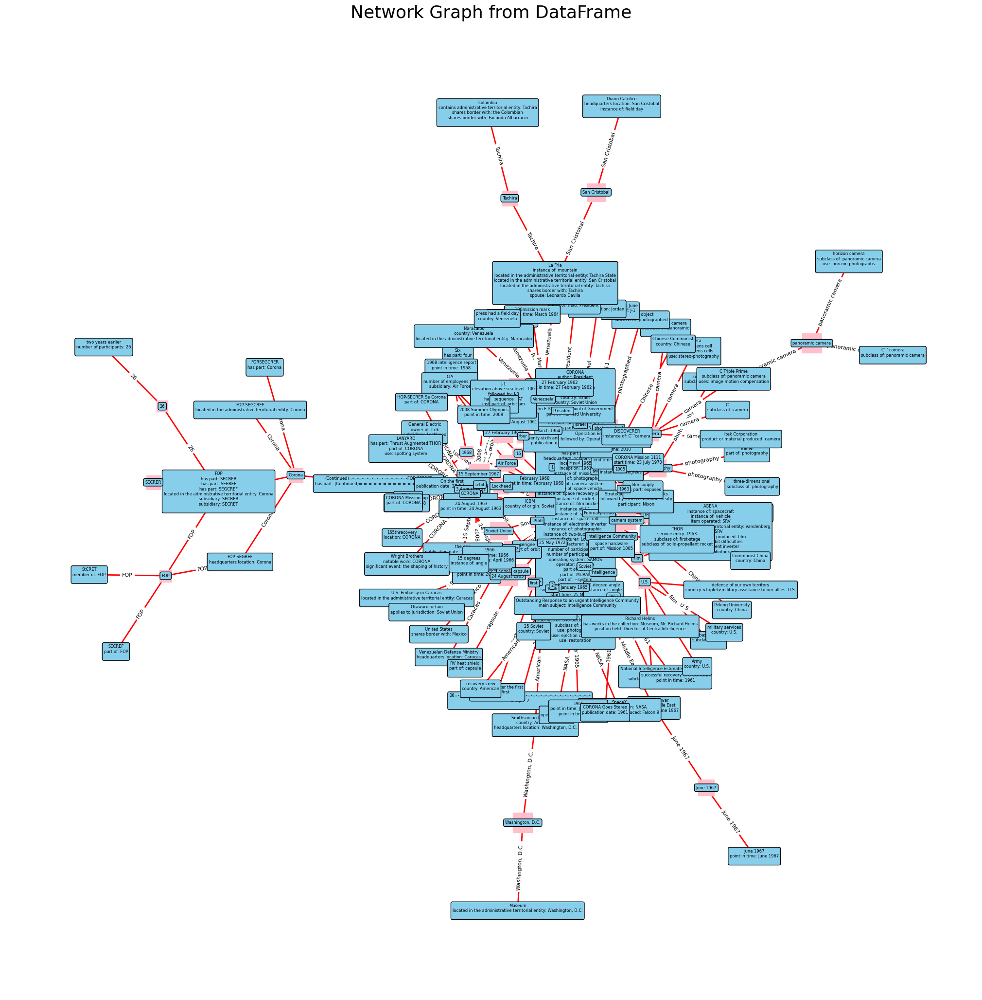

In [ ]:
source = df_TOC
document_1 = 'Greer_Studies_in_Intelligence_part_5'
document_2 = 'Greer_Studies_in_Intelligence_part_6'
document_3 = None
input_type = 'phrases'

network_graph_builder(source, document_1, document_2, document_3, input_type, 6, 1)


<div align="center">

*Figure 5.2.8: Network Graph - Chapters of Part 1 (Phrases)*

</div>

#### 5.2.5 Document: "List of Highest Priority Targets, USSR"

The final section - Section 5.2.5 uses the document *List of Highest Priority Targets, USSR* as input.  This document is interesting as it contains limited sentence-based text.  The document is largely a list of reconnaissance targets and their latitude / longitude coordinates.

The following two graphs use sentence-based inputs (Figure 5.2.7) and phrase-based inputs (Figure 5.2.8).

Not surprisingly, the REBEL model struggles to generate meaningful information.  The document is revisited in Section 6 below.

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


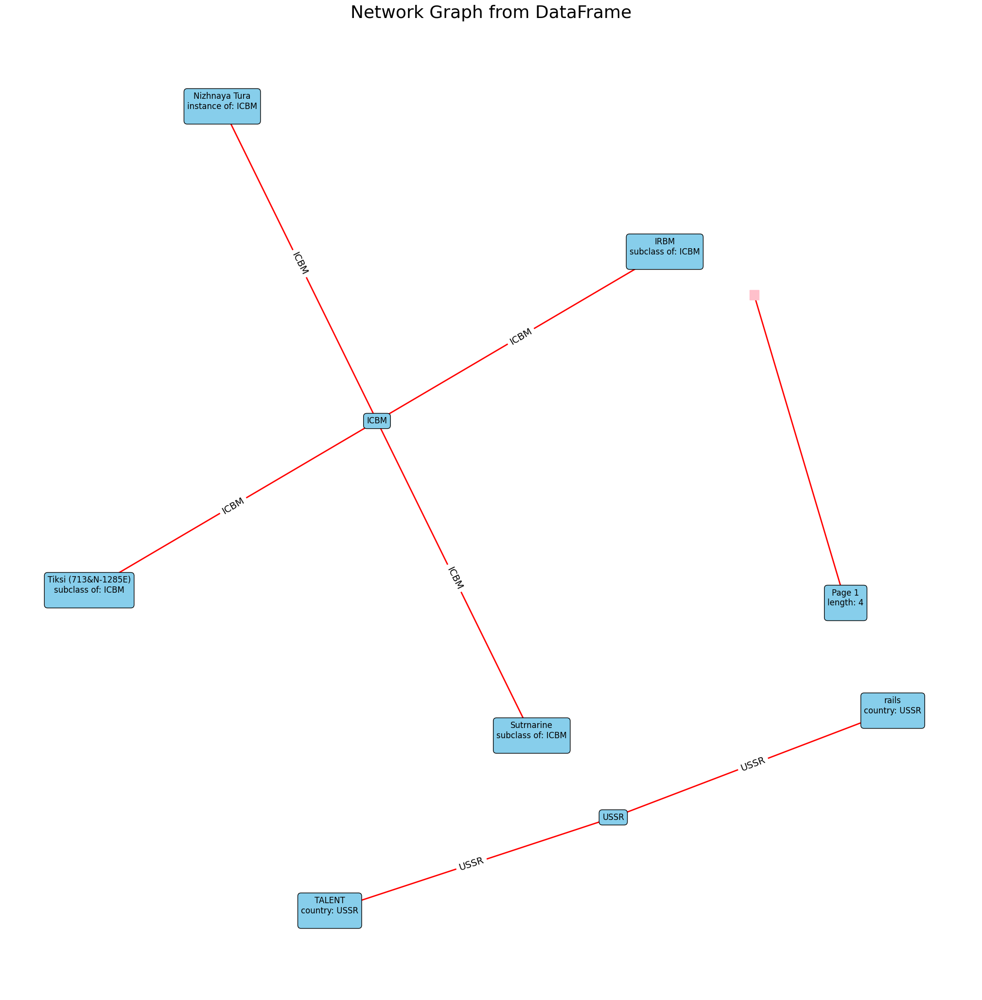

In [ ]:
source = df_TOC
document_1 = 'Highest_priority_targets'
document_2 = None
document_3 = None
input_type = 'sentences'

network_graph_builder(source, document_1, document_2, document_3, input_type, 12, 1)


<div align="center">

*Figure 5.2.7: Network Graph - List of Highest Priority Targets, USSR (Sentences)*

</div>

/tmp/ipython-input-3552372213.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35069 (\N{CJK UNIFIED IDEOGRAPH-88FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


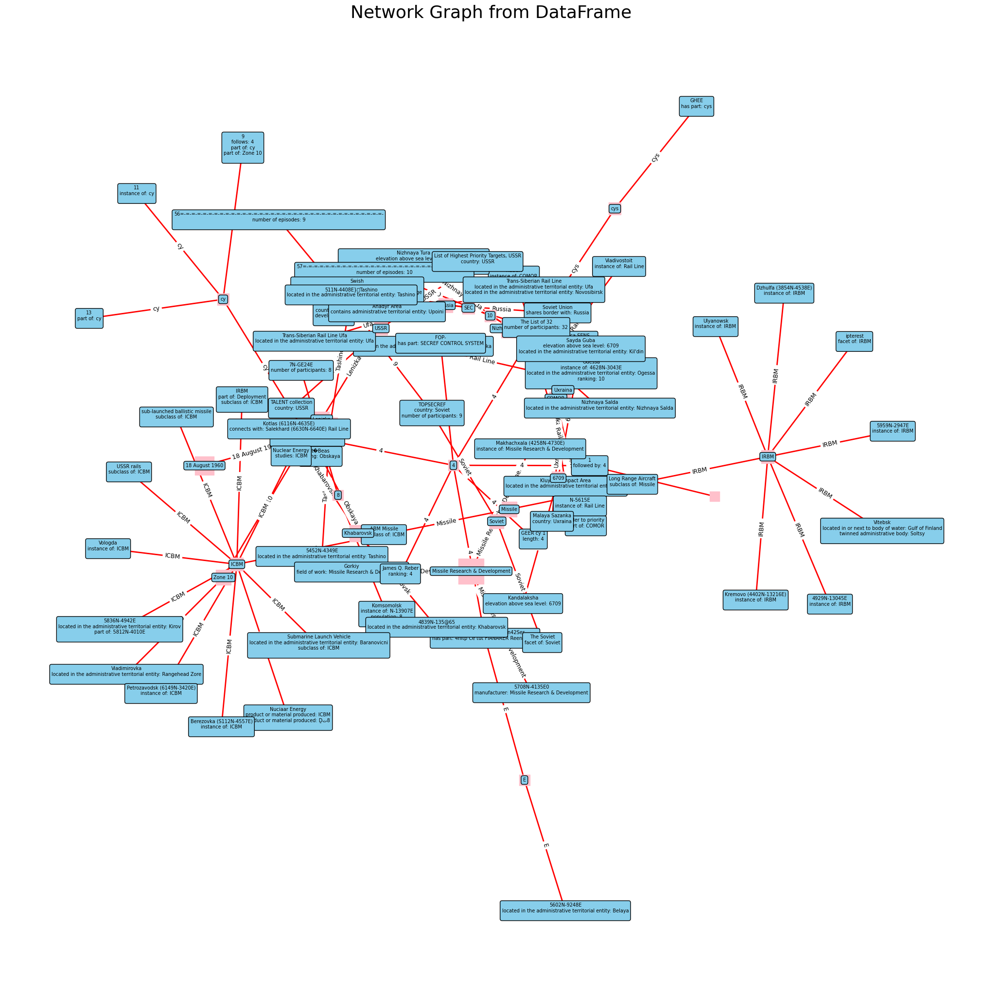

In [ ]:
source = df_TOC
document_1 = 'Highest_priority_targets'
document_2 = None
document_3 = None
input_type = 'phrases'

network_graph_builder(source, document_1, document_2, document_3, input_type, 7, 1)


<div align="center">

*Figure 5.2.8: Network Graph - List of Highest Priority Targets, USSR (Phrases)*

</div>

<a id="manual"></a>

## 6.0 Rules-Driven Model

As described above, some documents in the corpus are less well-suited to use of the REBEL model.  An example is the *List of Highest Priority Targets, USSR* portrayed in the network graphs in Figures 5.2.7 and 5.2.8.  The bulk of the document is tabular data identifying the name of the target (e.g., the city, facility, test range, etc.), its geographical latitude and longitude, and its category of interest (e.g., ICBM development, etc.).

### 6.1 Regular Expression Relationship Extraction

The functions below pre-process the digitized text correcting a number of known spelling mistakes and re-inserting white space in text where required.

The functions then extract the targets' categories of interest (e.g., ICBM deployment, etc.), latitude and longitude, and target names.  Finally, the relationship triplets are assembled in a dataframe repository.

In [ ]:
###  MOUNT GOOGLE DRIVE  ###
from google.colab import drive
drive.mount('/content/drive')

folder_path = r'/content/drive/MyDrive/89B Project Data Files/'

with open(folder_path + 'Highest_priority_targets', 'r', encoding = 'utf-8') as f:
    text = f.read()

print('\n', text[0:500])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 --- Page 1 ---
4. James Q. Reber, “List of Highest Priority Targets, USSR,” 18 August 1960

18 August 1960

LIST OF HIGHEST PRIORITY TARGETS ‘

Riya abii A) pei seeiereeepe SSR en. 4hitp Ce tut FIANARER Reen42Ses. =.

1. The List of 32 highest priority targets for TALENT collection
against the principal objective, USSR, is attached.’ As in previous lists, the
priority interest centers on: (a). The ICBM, IRBM, sub-launched ballistic
missiies; (b} The heavy bomber, and (c) Nuclear energy. However,


In [ ]:
# Restore white spaces in multi-token locations:
def white_space(input_text):
    updated_text = input_text[0]
    for i in range(1, len(input_text)):
        if i > 0 and input_text[i-1].islower() and input_text[i].isupper():
            updated_text = updated_text + ' ' + input_text[i]
        else:
            updated_text = updated_text + input_text[i]
    return updated_text

# Function to correct known miss-spellings:
def miss_spells(input_text):
    miss_spells_dict = {'Deploy': 'Deployment',
                        'sile': 'Missile',
                        'Produc': 'Production',
                        'Nuc': 'Nuclear',
                        'narine': 'Submarine',
                        'Arti': 'Anti-ICBM',
                        'Aircra': 'Aircraft',
                        'ergy': 'Energy',
                        'sion': '',
                        ':': ''}

    input_text_list = input_text.split()
    updated_text = ''
    for token in input_text_list:
        for key, value in miss_spells_dict.items():
            if key in token:
                token = value
        updated_text = updated_text + ' ' + token
    return updated_text

# Find Target categories of interest:
pattern_category_find = r'(Categor.*)(\n)(.*)'
match_target = re.findall(pattern_category_find, text)

category_pattern_1 = r'\d{4}E'
category_pattern_2 = r'alte'
category_pattern_3 = r': ipterest:'

# Find locations within individual text blocks defined by match_target:
pattern_location = r'.*\(\d{4}N-\d{4}E\)'
match_tuples_list = []

# Iterate through target matches and build 'concatenator' (string of categories of interest):
for i, term in enumerate(match_target):
    if i == 0:
        text_block = text[0: text.find(match_target[i][0])]
        match_location = re.findall(pattern_location, text_block)
        concatenator = term[0][term[0].find(':') + 2: ]
        concatenator = miss_spells(concatenator)
        if re.findall(category_pattern_1, term[2]) == [] and re.findall(category_pattern_2, term[2]) == []:
            concatenator = concatenator + ' ' + term[2]
            concatenator = miss_spells(concatenator)
        match_tuples_list.append((match_location, match_target[i], concatenator))

    elif i > 0 and i < len(match_target) - 1:
        text_block = text[text.find(match_target[i-1][0]): text.find(match_target[i][0])]
        match_location = re.findall(pattern_location, text_block)
        concatenator = term[0][term[0].find(':') + 2: ]
        if re.findall(category_pattern_1, term[2]) == [] and re.findall(category_pattern_2, term[2]) == []:
            concatenator = concatenator + ' ' + term[2]
        concatenator = re.sub(category_pattern_3, '', concatenator)
        concatenator = miss_spells(concatenator)
        match_tuples_list.append((match_location, match_target[i], concatenator))

    else:
        text_block = text[text.find(match_target[i][0]): ]
        match_location = re.findall(pattern_location, text_block)
        concatenator = term[0][term[0].find(':') + 2: ]
        concatenator = miss_spells(concatenator)
        if re.findall(category_pattern_1, term[2]) == [] and re.findall(category_pattern_2, term[2]) == []:
            concatenator = concatenator + ' ' + term[2]
            concatenator = miss_spells(concatenator)
        match_tuples_list.append((match_location, match_target[-1], concatenator))

# Build list of relationship heads (locations), tails (lat-long coordinates), and types (categories of interest):
head_list, tail_list, type_list = [], [], []
for paragraph in match_tuples_list:
    for location in paragraph[0]:
        if ' - ' in location:
            # Pre-hyphen (some lines of text have multiple locations separated by a hyphen):
            text_break = location.find(' - ')
            sub_text = location[0: text_break]
            location_sub_text = re.findall(r'^(.*?)\d{3}', sub_text)
            lat_long_sub_text = re.findall(r'\((.*?)\)', sub_text)
            clean_loc_sub_text = re.sub(r'[^a-zA-Z]', '', location_sub_text[0])
            clean_loc_sub_text = white_space(clean_loc_sub_text)
            head_list.append(clean_loc_sub_text)
            tail_list.append(lat_long_sub_text)
            type_list.append(paragraph[-1])

            # Post-hyphen:
            sub_text = location[text_break: ]
            location_sub_text = re.findall(r'^(.*?)\(\d{3}', sub_text)
            lat_long_sub_text = re.findall(r'\((.*?)\)', sub_text)
            clean_loc_sub_text = re.sub(r'[^a-zA-Z]', '', location_sub_text[0])
            clean_loc_sub_text = white_space(clean_loc_sub_text)
            head_list.append(clean_loc_sub_text)
            tail_list.append(lat_long_sub_text)
            type_list.append(paragraph[-1])
        else:
            location_sub_text = re.findall(r'^(.*?)\(\d{3}', location)
            lat_long_sub_text = re.findall(r'\((.*?)\)', location)
            clean_loc_sub_text = re.sub(r'[^a-zA-Z]', '', location_sub_text[0])
            clean_loc_sub_text = white_space(clean_loc_sub_text)
            head_list.append(clean_loc_sub_text)
            tail_list.append(lat_long_sub_text)
            type_list.append(paragraph[-1])

high_priority_targets_dict = {'Locations': head_list, 'Lat_long': tail_list, 'Interest_Category': type_list}
df_high_priority_targets = pd.DataFrame(high_priority_targets_dict)
df_high_priority_targets.head()

,Locations,Lat_long,Interest_Category
0,Kotlas,[6116N-4635E],ICBM Deployment
1,Salekhard,[6630N-6640E],ICBM Deployment
2,Ust Ukhta,[6338N-5353E],ICBM Deployment
3,Vorkuta,[6730N-6403E],ICBM Deployment
4,Polyarni Ural,[6602N-6510E],ICBM Deployment


### 6.2 Create Geographic Maps

The following code blocks generate geographic maps using the data repository generated above.  Target identifiers (e.g., target city names, etc.) are placed on the maps along with colored markers delineating the targets' category of interest.

#### 6.2.1 ICBM Deployment

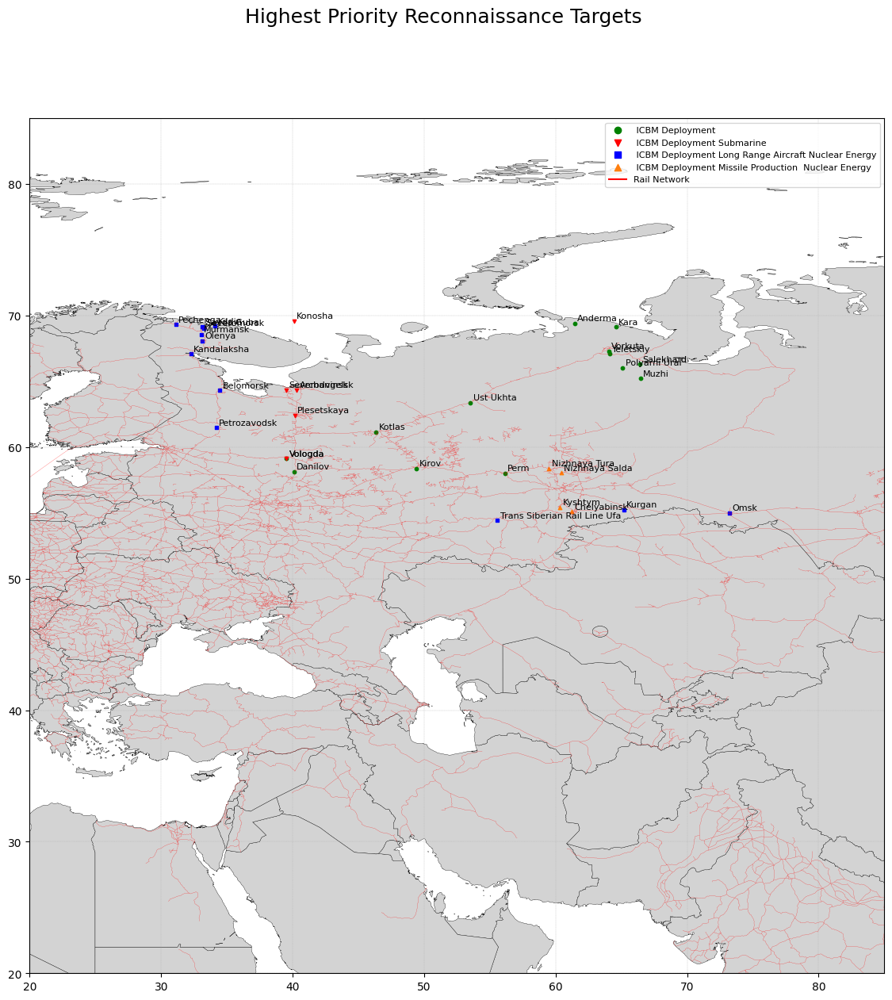

In [ ]:
folder_path = r'/content/drive/MyDrive/89B Project Data Files/'
file_name_1 = 'ne_10m_admin_0_countries.shp'
url_1 = folder_path + file_name_1

world = geopandas.read_file(url_1)

file_name_2 = 'ne_10m_railroads.shp'
url_2 = folder_path + file_name_2
railroads = geopandas.read_file(url_2)

fig, ax = plt.subplots(1, 1, figsize = (14, 14))
plt.suptitle('Highest Priority Reconnaissance Targets', fontsize = 18)

world.plot(ax = ax, color = 'lightgray', edgecolor = 'black', linewidth = 0.25)
railroads.plot(ax = ax, color = 'red', linewidth = 0.15)
ax.set_ylim([20, 85])
ax.set_xlim([20, 85])
ax.grid(linestyle = '--', linewidth = 0.25)

offset = 0.2
color_list = ['g', 'r', 'b', 'tab:orange', 'springgreen']
marker_list = ['o', 'v', 's', '^', 'x']
for combo, color, marker in zip(df_high_priority_targets['Interest_Category'].unique()[0:4], color_list, marker_list):
    temp_df = df_high_priority_targets[df_high_priority_targets['Interest_Category'] == combo]
    ax.scatter(0, 0, label = combo, marker = marker, color = color)
    for i in temp_df.index:
        y = int(temp_df.loc[i, 'Lat_long'][0][0:4]) / 100
        x = int(temp_df.loc[i, 'Lat_long'][0][-5:-1]) / 100
        ax.scatter(x, y, marker = marker, color = color, s = 10)

        ax.annotate(temp_df.loc[i, 'Locations'], xy = [x + offset, y + offset], fontsize = 8)
ax.plot([0, 1], [0, 1], label = 'Rail Network', color = 'r')
ax.legend(fontsize = 8);


#### 6.2.2 Missile Research & Development

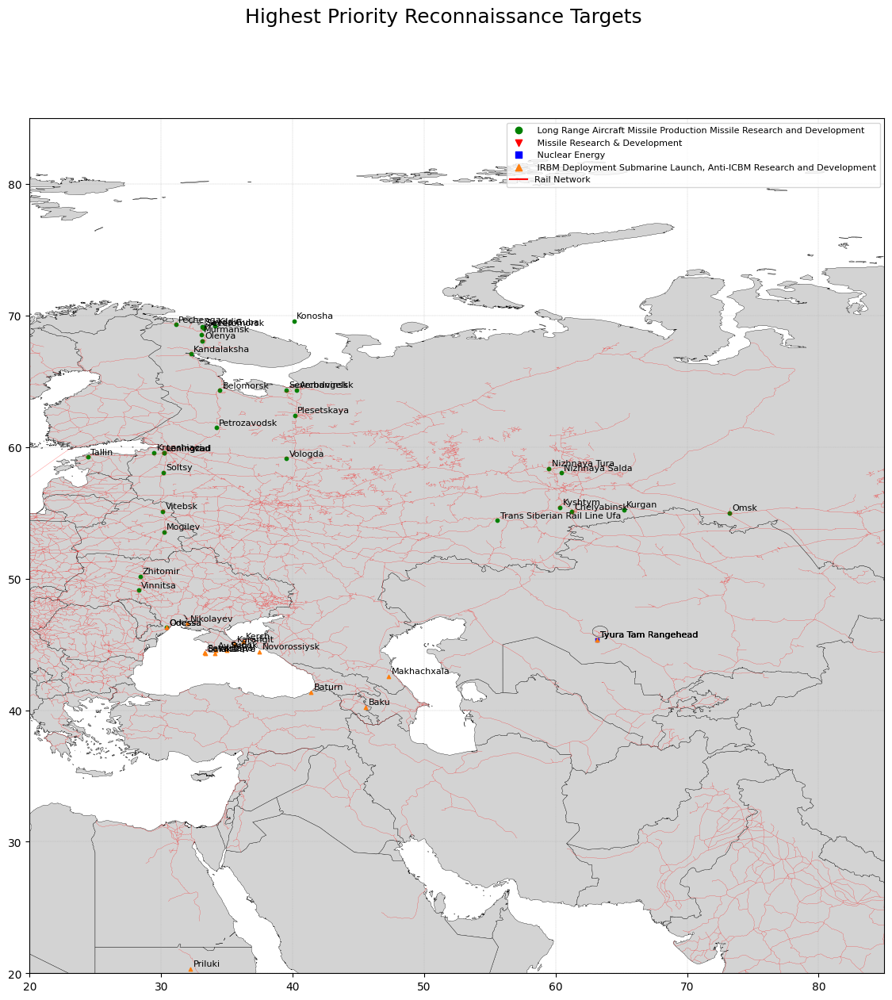

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (14, 14))
plt.suptitle('Highest Priority Reconnaissance Targets', fontsize = 18)

world.plot(ax = ax, color = 'lightgray', edgecolor = 'black', linewidth = 0.25)
railroads.plot(ax = ax, color = 'red', linewidth = 0.15)
ax.set_ylim([20, 85])
ax.set_xlim([20, 85])
# ax.set_xlim([20, 180])
ax.grid(linestyle = '--', linewidth = 0.25)

offset = 0.2
color_list = ['g', 'r', 'b', 'tab:orange', 'springgreen']
marker_list = ['o', 'v', 's', '^', 'x']
for combo, color, marker in zip(df_high_priority_targets['Interest_Category'].unique()[4:8], color_list, marker_list):
    temp_df = df_high_priority_targets[df_high_priority_targets['Interest_Category'] == combo]
    ax.scatter(0, 0, label = combo, marker = marker, color = color)
    for i in temp_df.index:
        y = int(temp_df.loc[i, 'Lat_long'][0][0:4]) / 100
        x = int(temp_df.loc[i, 'Lat_long'][0][-5:-1]) / 100
        ax.scatter(x, y, marker = marker, color = color, s = 10)

        ax.annotate(temp_df.loc[i, 'Locations'], xy = [x + offset, y + offset], fontsize = 8)
ax.plot([0, 1], [0, 1], label = 'Rail Network', color = 'r')
ax.legend(fontsize = 8);


#### 6.2.3 Missile Research & Development + ICBM Deployment

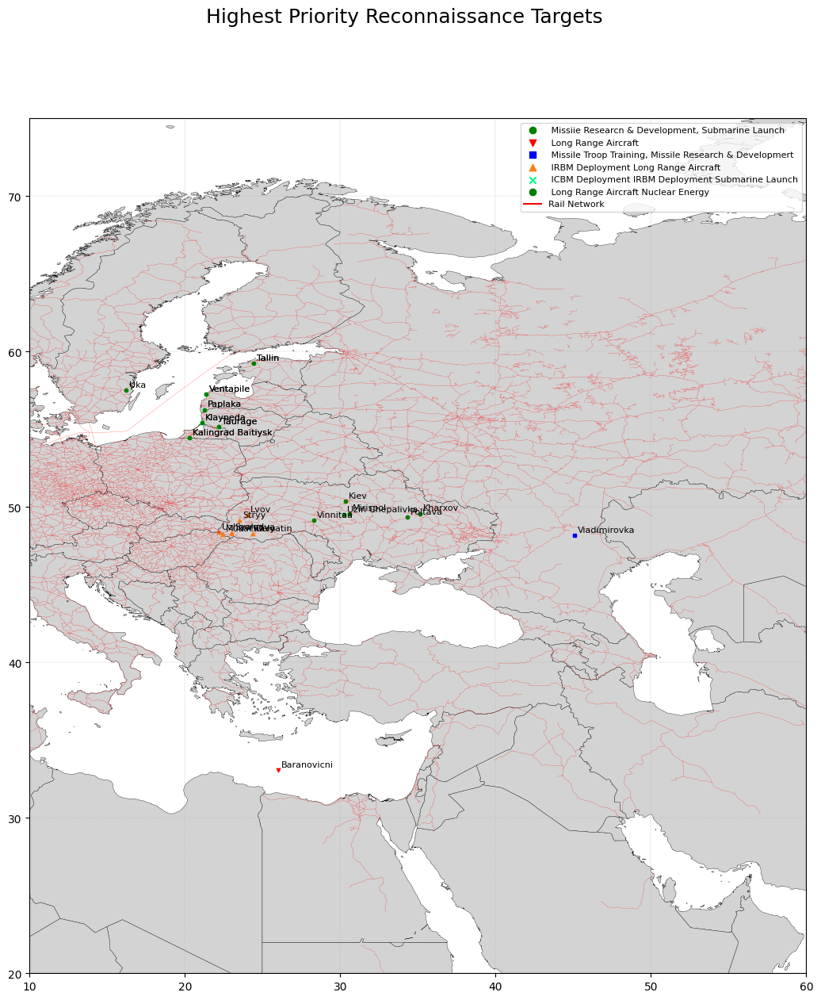

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (14, 14))
plt.suptitle('Highest Priority Reconnaissance Targets', fontsize = 18)

world.plot(ax = ax, color = 'lightgray', edgecolor = 'black', linewidth = 0.25)
railroads.plot(ax = ax, color = 'red', linewidth = 0.15)
ax.set_ylim([20, 75])
ax.set_xlim([10, 60])
ax.grid(linestyle = '--', linewidth = 0.25)

offset = 0.2
color_list = ['g', 'r', 'b', 'tab:orange', 'springgreen', 'g', 'r', 'b']
marker_list = ['o', 'v', 's', '^', 'x', 'o', 'v', 's']
for combo, color, marker in zip(df_high_priority_targets['Interest_Category'].unique()[8:14], color_list, marker_list):
    temp_df = df_high_priority_targets[df_high_priority_targets['Interest_Category'] == combo]
    ax.scatter(0, 0, label = combo, marker = marker, color = color)
    for i in temp_df.index:
        if len(temp_df.loc[i, 'Lat_long']) > 0:
            y = int(temp_df.loc[i, 'Lat_long'][0][0:4]) / 100
            x = int(temp_df.loc[i, 'Lat_long'][0][-5:-1]) / 100
            ax.scatter(x, y, marker = marker, color = color, s = 10)

            ax.annotate(temp_df.loc[i, 'Locations'], xy = [x + offset, y + offset], fontsize = 8)
ax.plot([0, 1], [0, 1], label = 'Rail Network', color = 'r')
ax.legend(fontsize = 8);
